In [1]:
# Uncomment to install required libraries
# pip install beautifulsoup4 langchain_community langchain langchain_core chromadb pymupdf tiktoken openai

# install "sentence-transformers" only for local runs. It is already installed in Cloud platforms like "Google Colab"
# pip install sentence-transformers 

In [2]:
# Libraries for file handling and token counting
import json, os
import tiktoken

#Libraries for Loading Data, Chunking, Embedding, and Vector Databases
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_community.embeddings.sentence_transformer import SentenceTransformerEmbeddings
from langchain_community.vectorstores import Chroma

# Importing the OpenAI client (used to call the LLM via the GL Proxy)
from openai import OpenAI

/var/folders/0_/p_pycfq9797_jqjlh9rhvwd80000gn/T/ipykernel_58788/1261765445.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


In [3]:
import argparse
import re
import sys
import time
from dataclasses import dataclass, asdict
from datetime import date, datetime, timedelta
from urllib.parse import urljoin, urlparse
from pathlib import Path

import requests
from bs4 import BeautifulSoup

# Overview 
- The workflow that produces newsletter of regulatory update in the IRRBB risk framework is presented below.
- For simplicity, only **BCBS** framework is included. Inclusion of US, EU, EBA legislations is planned.

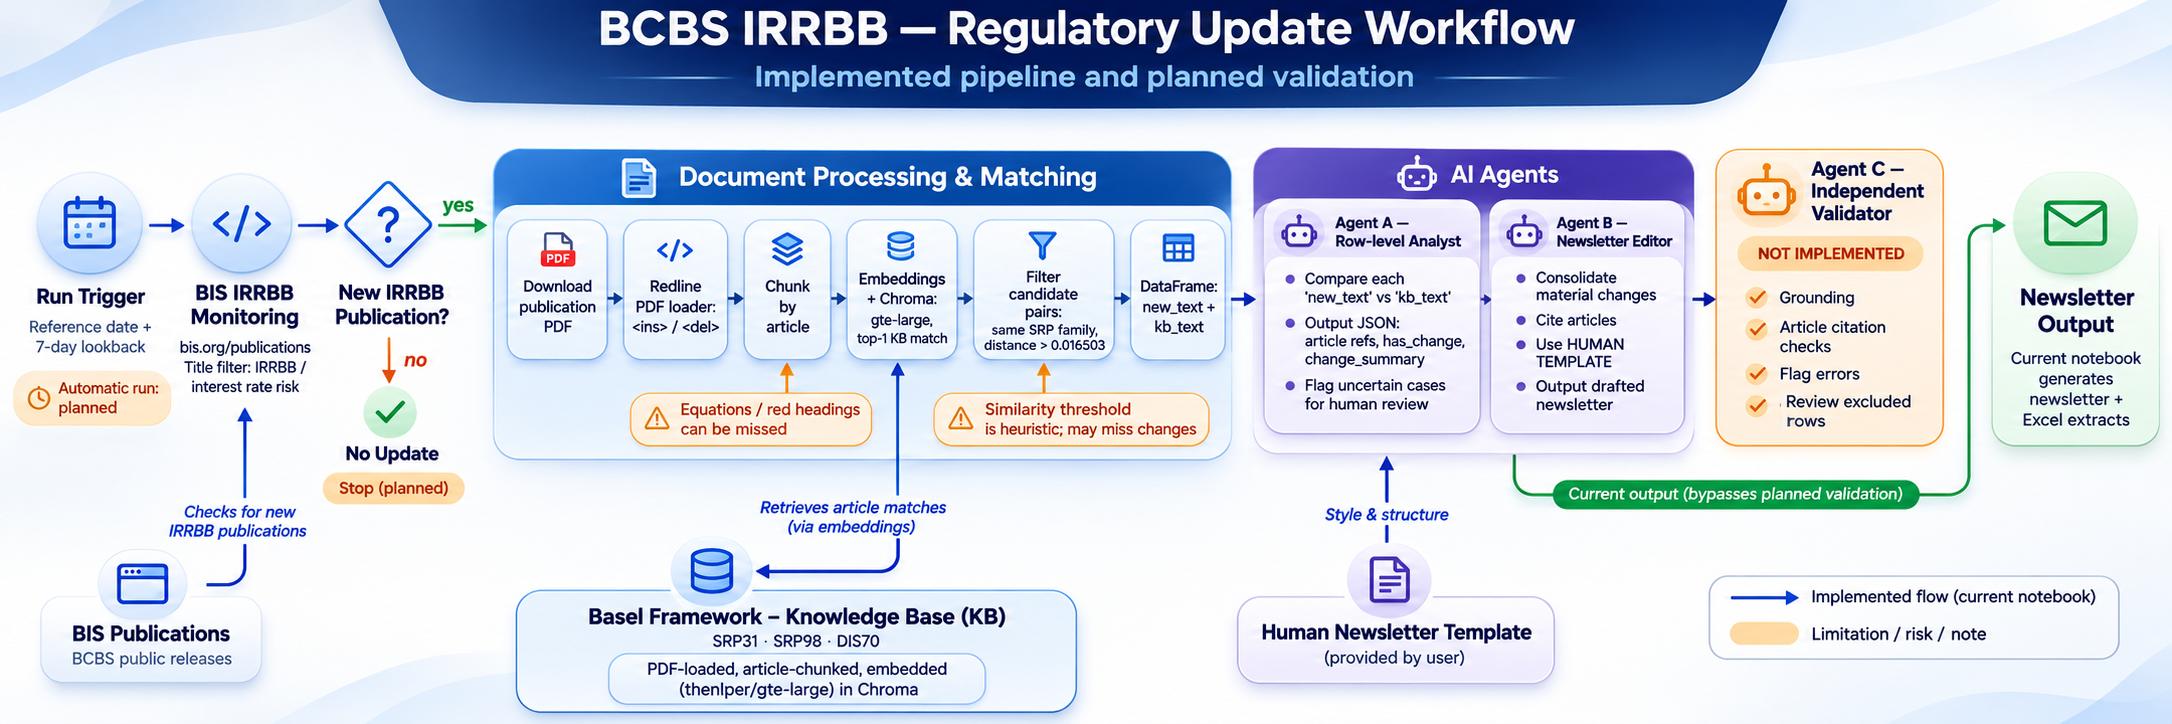

# Read the BIS website for the new regulatory publication (https://www.bis.org/publications)

In [5]:
# Configuration
# --------------------------------------------------------------------------- #
REFERENCE_DATE = "11.11.26"            # dd.mm.yy
LOOKBACK_DAYS = 7
KEYWORDS = ["IRRBB", "interest rate risk"]   # "interest rate risk" is ONE phrase
 
BASE_URL = "https://www.bis.org"
LIST_URL = BASE_URL + "/publications"
MAX_PAGES = 30                         # safety cap on pagination
REQUEST_DELAY_S = 1.0                  # be polite to the server
TIMEOUT_S = 30
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; irrbb-watch/0.1; internal research tool)"}
 
MONTHS = {m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}
DATE_RE = re.compile(
    r"\b(\d{1,2})\s+(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\.?\s+(\d{4})\b", re.I)
 
 
# --------------------------------------------------------------------------- #
# Data model
# --------------------------------------------------------------------------- #
@dataclass
class Publication:
    date: date
    title: str
    url: str
    title_source: str   # "markup" = taken from the page text, "slug" = rebuilt from the URL
 
    def to_dict(self):
        d = asdict(self)
        d["date"] = self.date.isoformat()
        return d
 
 
# --------------------------------------------------------------------------- #
# Fetching
# --------------------------------------------------------------------------- #
def fetch_page(page: int, retries: int = 3) -> str:
    """Page numbers are 0-based on bis.org (?page=0 is the first page)."""
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(LIST_URL, params={"page": page}, headers=HEADERS, timeout=TIMEOUT_S)
            r.raise_for_status()
            return r.text
        except requests.RequestException as e:
            last_err = e
            time.sleep(2 * attempt)
    raise RuntimeError(f"Could not fetch page {page}: {last_err}")
 
 
# --------------------------------------------------------------------------- #
# Parsing
# --------------------------------------------------------------------------- #
def parse_date(match: re.Match) -> date:
    day, mon, year = match.groups()
    return date(int(year), MONTHS[mon[:3].lower()], int(day))
 
 
def title_from_slug(url: str) -> str:
    slug = urlparse(url).path.rstrip("/").split("/")[-1]
    return re.sub(r"\s+", " ", slug.replace("-", " ")).strip()
 
 
def extract_title(lines: list, date_line_idx: int, date_match: re.Match, url: str):
    """
    Preferred: the title is the text right after the date (same line or next line),
    which works when title and teaser are separate elements in the markup.
    Fallback: if everything is flattened into one line we cannot separate title
    from teaser, so we rebuild the title from the URL slug.
    """
    if len(lines) > 1:
        remainder = lines[date_line_idx][date_match.end():].strip()
        if remainder:
            return remainder, "markup"
        if date_line_idx + 1 < len(lines):
            return lines[date_line_idx + 1], "markup"
    return title_from_slug(url), "slug"
 
 
def parse_listing(html: str) -> list:
    """Return the publications found on one listing page (deduplicated by URL)."""
    soup = BeautifulSoup(html, "html.parser")
    found = {}
    for a in soup.find_all("a", href=True):
        url = urljoin(BASE_URL, a["href"])
        path = urlparse(url).path
        if not path.startswith("/publications/"):
            continue
        lines = [ln.strip() for ln in a.get_text("\n").split("\n") if ln.strip()]
        if not lines:
            continue
        # the date can sit on any line of the item; find it
        for idx, ln in enumerate(lines):
            m = DATE_RE.search(ln)
            if m:
                break
        else:
            continue   # navigation links and empty duplicate anchors have no date: skip
        title, source = extract_title(lines, idx, m, url)
        found[url] = Publication(parse_date(m), title, url, source)
    return list(found.values())
 
 
# --------------------------------------------------------------------------- #
# Filtering
# --------------------------------------------------------------------------- #
def build_patterns(keywords):
    pats = []
    for kw in keywords:
        # words joined by whitespace OR hyphen, so slug-based titles match too
        body = r"[\s\-]+".join(re.escape(w) for w in kw.split())
        pats.append(re.compile(r"\b" + body + r"\b", re.I))
    return pats
 
 
def title_matches(title: str, patterns) -> bool:
    return any(p.search(title) for p in patterns)
 
 
# --------------------------------------------------------------------------- #
# Collection
# --------------------------------------------------------------------------- #
def collect_window(window_start: date, window_end: date, fetch=None) -> list:
    """Walk the listing (newest first) until a whole page is older than the window."""
    fetch = fetch or fetch_page
    in_window, seen = [], set()
    for page in range(MAX_PAGES):
        items = parse_listing(fetch(page))
        if not items:
            if page == 0:
                # IMPORTANT: this is a failure, not "no update"
                raise RuntimeError(
                    "Parsed 0 publications on page 0: the page layout probably changed or the "
                    "request was blocked. This is NOT the same as 'no update'.")
            break
        for it in items:
            if it.url in seen:
                continue
            seen.add(it.url)
            if window_start <= it.date <= window_end:
                in_window.append(it)
        if all(it.date < window_start for it in items):
            break
        time.sleep(REQUEST_DELAY_S)
    return in_window
 
 
def run(reference_date: str = REFERENCE_DATE, days: int = LOOKBACK_DAYS,
        json_path: str = None, keywords=None) -> list:
    """
    Do the whole job and return the matching Publication objects.
    Call this directly from a notebook:   matches = run("11.11.26", 7)
    """
    keywords = keywords or KEYWORDS
    ref = datetime.strptime(reference_date, "%d.%m.%y").date()
    start = ref - timedelta(days=days)
    patterns = build_patterns(keywords)
 
    print(f"Window: {start:%d.%m.%Y} to {ref:%d.%m.%Y} (inclusive) | keywords: {keywords}")
    publications = collect_window(start, ref)
    print(f"Publications in window: {len(publications)}")
 
    matches = [p for p in publications if title_matches(p.title, patterns)]
    if not matches:
        print("no update")
    else:
        for p in sorted(matches, key=lambda x: x.date, reverse=True):
            flag = "" if p.title_source == "markup" else "  [title rebuilt from URL]"
            print(f"- {p.date:%d.%m.%Y} | {p.title}{flag}\n  {p.url}")
 
    if json_path:
        with open(json_path, "w", encoding="utf-8") as f:
            json.dump([p.to_dict() for p in matches], f, indent=2, ensure_ascii=False)
        print(f"Saved {len(matches)} match(es) to {json_path}")
    return matches
 
 
def main(argv=None):
    ap = argparse.ArgumentParser(description="BIS publications watcher (listing + title filter)")
    ap.add_argument("--reference-date", default=REFERENCE_DATE, help="dd.mm.yy (default %(default)s)")
    ap.add_argument("--days", type=int, default=LOOKBACK_DAYS, help="look-back days (default %(default)s)")
    ap.add_argument("--json", help="optional path to save matches as JSON")
    # parse_known_args: ignores extra arguments such as Jupyter's "-f kernel-xxx.json"
    args, _unknown = ap.parse_known_args(argv)
    return run(args.reference_date, args.days, args.json)
 
 
def _in_notebook() -> bool:
    return "ipykernel" in sys.modules
 
 
if __name__ == "__main__":
    try:
        main()
    except Exception as e:
        if _in_notebook():
            raise                      # show the normal traceback in Jupyter
        print(f"ERROR: {e}", file=sys.stderr)
        sys.exit(1)

Window: 04.11.2026 to 11.11.2026 (inclusive) | keywords: ['IRRBB', 'interest rate risk']
Publications in window: 6
- 09.11.2026 | Interest rate risk in the banking book – additional Pillar 2 guidance
  https://www.bis.org/publications/interest-rate-risk-banking-book---additional-pillar-2-guidance


## Download the pubblication

In [6]:
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; irrbb-watch/0.1; internal research tool)"}

def _pdf_candidates(page_url: str, html: str) -> list:
    """Ordered list of URLs that might be the publication's PDF."""
    import re
    from urllib.parse import urljoin, urlparse
    from bs4 import BeautifulSoup

    slug = urlparse(page_url).path.rstrip("/").split("/")[-1]
    slug_norm = re.sub(r"-{2,}", "-", slug)      # page slug has '---', the PDF name has '-'

    pdf_links = []
    for a in BeautifulSoup(html, "html.parser").find_all("a", href=True):
        href = a["href"].split("#")[0]
        if href.split("?")[0].lower().endswith(".pdf"):
            pdf_links.append(urljoin(page_url, href))

    matching = [u for u in pdf_links if slug_norm in u]      # PDF named after this page
    others = [u for u in pdf_links if slug_norm not in u]    # e.g. older d###.pdf, related docs
    constructed = [urljoin(page_url, f"/publications/{slug_norm}.pdf"),
                   page_url.split("?")[0].rstrip("/") + ".pdf"]

    ordered, seen = [], set()
    for u in matching + constructed + others[:1]:            # only ONE unrelated link, last resort
        if u not in seen:
            seen.add(u)
            ordered.append(u)
    return ordered


def _fetch_pdf_bytes(url: str):
    """Return the bytes if the URL really serves a PDF, otherwise None."""
    import requests
    try:
        r = requests.get(url, headers=HEADERS, timeout=60)
    except requests.RequestException:
        return None
    if r.status_code == 200 and r.content[:5] == b"%PDF-":
        return r.content
    return None


def download_publication_pdf(page_url: str, out_dir=None, overwrite: bool = False) -> Path:
    """Download the PDF of a bis.org publication page into out_dir (default: working directory)."""
    import requests
    from urllib.parse import urlparse

    out_dir = Path(out_dir) if out_dir else Path.cwd()
    out_dir.mkdir(parents=True, exist_ok=True)

    if urlparse(page_url).path.lower().endswith(".pdf"):
        candidates = [page_url]
    else:
        r = requests.get(page_url, headers=HEADERS, timeout=30)
        r.raise_for_status()
        candidates = _pdf_candidates(page_url, r.text)

    tried = []
    for url in candidates:
        target = out_dir / Path(urlparse(url).path).name
        if target.exists() and not overwrite:
            print(f"Already in working directory, reusing: {target}")
            return target
        content = _fetch_pdf_bytes(url)
        tried.append(url)
        if content:
            target.write_bytes(content)
            print(f"Downloaded {url}\nSaved to   {target}  ({len(content) / 1024:.0f} KB)")
            return target

    raise RuntimeError("No PDF found for this publication. URLs tried:\n  " + "\n  ".join(tried))


# ---- run: get the matches from the watcher, then download ----
matches = run(REFERENCE_DATE, LOOKBACK_DAYS)
if matches:
    pdf_path = download_publication_pdf(matches[0].url)
else:
    print("no matching publication - nothing to download")

Window: 04.11.2026 to 11.11.2026 (inclusive) | keywords: ['IRRBB', 'interest rate risk']
Publications in window: 6
- 09.11.2026 | Interest rate risk in the banking book – additional Pillar 2 guidance
  https://www.bis.org/publications/interest-rate-risk-banking-book---additional-pillar-2-guidance
Already in working directory, reusing: /Users/dima/interest-rate-risk-banking-book-additional-pillar-2-guidance_0.pdf


In [7]:
pdf_loader = PyMuPDFLoader(pdf_path)
doc = pdf_loader.load()

## Process the regulatory update pdf

In [8]:
print(doc[15].page_content,end="\n") 

12 
Interest rate risk in the banking book
 
 
(1) 
internally selected interest rate shock scenarios addressing the bank’s risk profile, 
according to its ICAAP; 
(2) 
historical and hypothetical interest rate stress scenarios, which tend to be more severe 
than shock scenarios; 
(3) 
the six prescribed interest rate shock scenarios set out in [SRP31.94] to [SRP31.97]; and 
(4) 
any additional interest rate shock scenarios required by supervisors. 
31.31 
Banks should measure their vulnerability to loss under stressful market conditions – including the 
breakdown of key assumptions – and consider those results when establishing and reviewing 
their policies and limits for IRRBB. 
31.32 
A bank should develop and implement an effective stress testing framework for IRRBB as part of 
its broader risk management and governance processes. This should feed into the decision-
making process at the appropriate management level, including strategic decisions (eg business 
and capital planning 

#### Observation
- the extracted pdf fails to distinguish the red text (additions) and the strikethrough text (deletions)
- this drawback undermines significantly the model's capacity to clearly identify innovations in the new regulation

Exhibit of the updated regulation SRP31.31 to SRP31.36 is reported below:
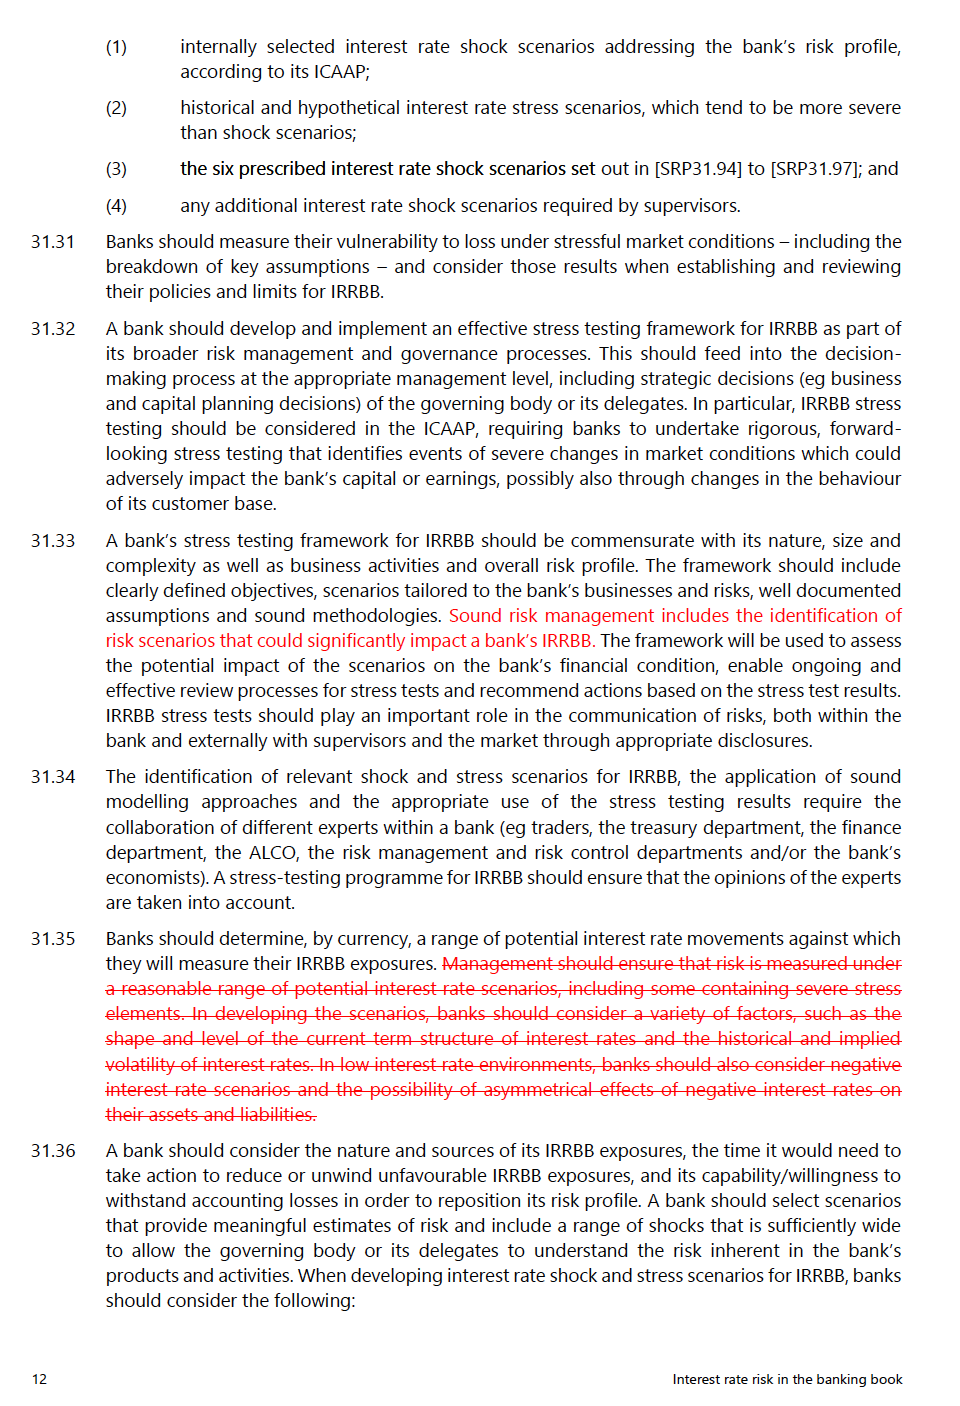

To preserve red text (additions) and strikethrough text (deletions) for LangChain, we build a custom LangChain document loader using PyMuPDF (fitz / pymupdf) directly

In [9]:
import pymupdf  # PyMuPDF
from langchain_core.documents import Document
from langchain_core.document_loaders import BaseLoader


class RedlinePDFLoader(BaseLoader):
    def __init__(self, file_path: str):
        self.file_path = file_path

    def _is_red(self, color_int: int) -> bool:
        """Check if an sRGB integer represents a predominantly red color."""
        r = (color_int >> 16) & 255
        g = (color_int >> 8) & 255
        b = color_int & 255
        # Adjust thresholds if your PDF uses dark red or maroon
        return r > 150 and g < 80 and b < 80

    def _get_strikethrough_rects(self, page: pymupdf.Page) -> list[pymupdf.Rect]:
        """Collect bounding boxes from both StrikeOut annotations and horizontal vector lines."""
        strike_rects = []

        # 1. Check formal PDF StrikeOut annotations (type 11)
        for annot in page.annots():
            if annot.type[0] == pymupdf.PDF_ANNOT_STRIKE_OUT:
                strike_rects.append(annot.rect)

        # 2. Check drawn horizontal vector lines (common in Word/Acrobat tracked changes)
        for path in page.get_drawings():
            rect = path["rect"]
            # A strikethrough line is wide and very thin vertically
            if rect.width > 5 and rect.height < 3:
                strike_rects.append(rect)

        return strike_rects

    def _is_struck_through(
        self, span_bbox: tuple, strike_rects: list[pymupdf.Rect]
    ) -> bool:
        """Check if a horizontal line passes through the vertical middle of the text span."""
        s_rect = pymupdf.Rect(span_bbox)
        mid_y = (s_rect.y0 + s_rect.y1) / 2
        tolerance = s_rect.height * 0.25  # Allow slight vertical offset (use lower values to

        for l_rect in strike_rects:
            # Horizontal overlap check
            x_overlap = min(s_rect.x1, l_rect.x1) - max(s_rect.x0, l_rect.x0)
            if x_overlap > (s_rect.width * 0.5):
                # Vertical alignment near center of text
                line_y = (l_rect.y0 + l_rect.y1) / 2
                if abs(line_y - mid_y) <= tolerance:
                    return True
        return False

    def lazy_load(self):
        doc = pymupdf.open(self.file_path)

        for page_num, page in enumerate(doc):
            strike_rects = self._get_strikethrough_rects(page)
            page_dict = page.get_text("dict")
            formatted_lines = []

            for block in page_dict.get("blocks", []):
                if block.get("type") != 0:  # Skip image blocks
                    continue

                for line in block.get("lines", []):
                    line_parts = []
                    for span in line.get("spans", []):
                        text = span["text"]
                        if not text.strip():
                            line_parts.append(text)
                            continue

                        is_red = self._is_red(span["color"])
                        is_struck = self._is_struck_through(span["bbox"], strike_rects)

                        # Tag text based on visual formatting
                        if is_struck:
                            line_parts.append(f"<del>{text}</del>")
                        elif is_red:
                            line_parts.append(f"<ins>{text}</ins>")
                        else:
                            line_parts.append(text)

                    formatted_lines.append("".join(line_parts))

            yield Document(
                page_content="\n".join(formatted_lines),
                metadata={"source": self.file_path, "page": page_num},
            )


The script extracts text spans, tags red text as "ins" (new) and struck-through text as "del" (canceled), and returns standard LangChain Document objects

In [10]:
loader = RedlinePDFLoader(pdf_path)
docs = loader.load()

print(docs[15].page_content,end="\n") 

 
12 
Interest rate risk in the banking book
 
 
(1) 
internally selected interest rate shock scenarios addressing the bank’s risk profile, 
according to its ICAAP; 
(2) 
historical and hypothetical interest rate stress scenarios, which tend to be more severe 
than shock scenarios; 
(3) 
the six prescribed interest rate shock scenarios set out in [SRP31.94] to [SRP31.97]; and 
(4) 
any additional interest rate shock scenarios required by supervisors. 
31.31 
Banks should measure their vulnerability to loss under stressful market conditions – including the 
breakdown of key assumptions – and consider those results when establishing and reviewing 
their policies and limits for IRRBB. 
31.32 
A bank should develop and implement an effective stress testing framework for IRRBB as part of 
its broader risk management and governance processes. This should feed into the decision-
making process at the appropriate management level, including strategic decisions (eg business 
and capital plannin

## Chunk the regulatory update pdf
- LLMs have a restricted "context window" (the maximum amount of text they can read at one time)
- Chunking is the process of breaking large documents or text inputs into smaller, manageable segments (or "chunks")
- Smaller, targeted chunks reduce noise, lower token costs, and prevent the AI from missing fine details buried in a massive text block
- The main parameter for chunking algos is the size of chunked text (number of tokens). In case of the regulatory text, the most obvious discriminat for text separation is the article number. We implement this logic below

In [11]:
# Define chunking rule (article number)
# Explicit article headings: Article 1, Art. 5, Art.12, etc.
ARTICLE_RE = re.compile(
    r"""
    ^[ \t]*(?:\#{1,6}[ \t]+)?
    (?P<kind>Article|Art\.?)
    (?:[ \t]*(?P<id>
        \d+(?:\.\d+)*[A-Za-z]?
        |[IVXLCDM]+
    ))?
    (?=$|[ \t]|[:\-–—]|\.(?!\d))
    """,
    re.IGNORECASE | re.VERBOSE
)

# Pure numeric provisions: 31.1, 98.20, 125.15, 1.2.3
NUMERIC_RE = re.compile(
    r"""
    ^[ \t]*(?:\#{1,6}[ \t]+)?
    (?P<id>\d+(?:\.\d+)+)
    (?=$|[ \t]|[:\-–—]|\.(?!\d))
    """,
    re.VERBOSE
)

# Article followed by its number on the next line
ID_ON_NEXT_LINE = re.compile(
    r"^[ \t]*(\d+(?:\.\d+)*[A-Za-z]?|[IVXLCDM]+)\.?[ \t]*$",
    re.IGNORECASE
)

# Ignore obvious table-of-contents entries
TOC_LINE = re.compile(
    r"(?:\.{3,}|…{2,})\s*\d+\s*$"
)


def chunk_by_article(
    doc: Document | list[Document],
    *,
    numeric_levels=(2,),
    keep_preamble=False
) -> list[Document]:
    """
    Split a regulatory Document into article-level chunks.

    Parameters
    ----------
    doc : Document or list[Document]
        LangChain Document (or list of) containing the regulatory text.

    numeric_levels : tuple
        Accepted numbering depths:
        (2,)    -> 31.1, 98.20, 125.15
        (2, 3)  -> also 12.3.1

    keep_preamble : bool
        Whether to retain text before the first article.

    Returns
    -------
    list[Document]
        One Document per detected article.
    """
    
    # Convert list of page Documents into a single Document
    if isinstance(doc, list):
        if not doc:
            return []

        doc = Document(
            page_content="\n\n".join(d.page_content for d in doc),
            metadata={
                "source": doc[0].metadata.get("source"),
                "total_pages": len(doc)
            }
        )
        
    text = doc.page_content
    lines = text.splitlines(keepends=True)

    # Calculate the character offset of every line
    starts = []
    pos = 0

    for line in lines:
        starts.append(pos)
        pos += len(line)

    boundaries = []
    consumed_number_lines = set()

    # Step 1: Detect article boundaries
    for i, line in enumerate(lines):

        if i in consumed_number_lines:
            continue

        stripped = line.rstrip("\r\n")

        # Ignore obvious TOC entries
        if TOC_LINE.search(stripped):
            continue

        # A. Article / Art. headings
        art = ARTICLE_RE.match(stripped)

        if art:
            label = art.group("kind")
            ident = art.group("id")

            if ident is None:
                # Bare Article / Art. must occupy the line
                if stripped[art.end():].strip():
                    continue

                # Check whether number is on next line
                if i + 1 < len(lines):
                    following = ID_ON_NEXT_LINE.fullmatch(
                        lines[i + 1].rstrip("\r\n")
                    )

                    if following:
                        ident = following.group(1)
                        consumed_number_lines.add(i + 1)

            boundaries.append(
                (starts[i], ident, label, "article")
            )
            continue

        # B. Pure numeric article identifiers
        num = NUMERIC_RE.match(stripped)

        if num:
            ident = num.group("id")

            if len(ident.split(".")) not in numeric_levels:
                continue

            boundaries.append(
                (
                    starts[i],
                    ident,
                    ident,
                    "numbered_provision"
                )
            )

    # Step 2: Handle documents without detected articles
    if not boundaries:
        if not text.strip():
            return []

        return [
            Document(
                page_content=text,
                metadata={
                    **doc.metadata,
                    "chunk_type": "unsegmented"
                }
            )
        ]

    chunks = []

    # Optional preamble
    if keep_preamble:
        first_start = boundaries[0][0]
        preamble = text[:first_start].strip()

        if preamble:
            chunks.append(
                Document(
                    page_content=preamble,
                    metadata={
                        **doc.metadata,
                        "chunk_type": "preamble",
                        "char_start": 0,
                        "char_end": first_start
                    }
                )
            )

    # Step 3: Split between consecutive boundaries
    for i, (start, ident, label, kind) in enumerate(boundaries):

        end = (
            boundaries[i + 1][0]
            if i + 1 < len(boundaries)
            else len(text)
        )

        content = text[start:end].strip()

        if not content:
            continue

        chunks.append(
            Document(
                page_content=content,
                metadata={
                    **doc.metadata,
                    "article_id": ident,
                    "article_heading": label,
                    "chunk_type": kind,
                    "chunk_index": len(chunks),
                    "char_start": start,
                    "char_end": end
                }
            )
        )

    return chunks


In [12]:
chunks = chunk_by_article(docs)

In [13]:
chunks[35].page_content #article 31.36

'31.36 \nA bank should consider the nature and sources of its IRRBB exposures, the time it would need to \ntake action to reduce or unwind unfavourable IRRBB exposures, and its capability/willingness to \nwithstand accounting losses in order to reposition its risk profile. A bank should select scenarios \nthat provide meaningful estimates of risk and include a range of shocks that is sufficiently wide \nto allow the governing body or its delegates to understand the risk inherent in the bank’s \nproducts and activities. When developing interest rate shock and stress scenarios for IRRBB, banks \nshould consider the following: \n\n \nInterest rate risk in the banking book \n13 \n \n(1) \nThe scenarios should be sufficiently wide-ranging to identify parallel and non-parallel \ngap risk, basis risk and option risk. In many cases, static interest rate shocks may be \ninsufficient to assess IRRBB exposure adequately. Banks should ensure that the scenarios \nare both severe and plausible, in l

#### Observation
- The chunk handles correctly case when article is split into two separate pages.
- The chunk is robust to article's inner (number) bullet points.
- The new updated text (bullet 6) is correctly identified by 'ins' (start insert) and '/ins' (end insert) separators.

Exhibit of the updated regulation SRP31.36 is reported below:
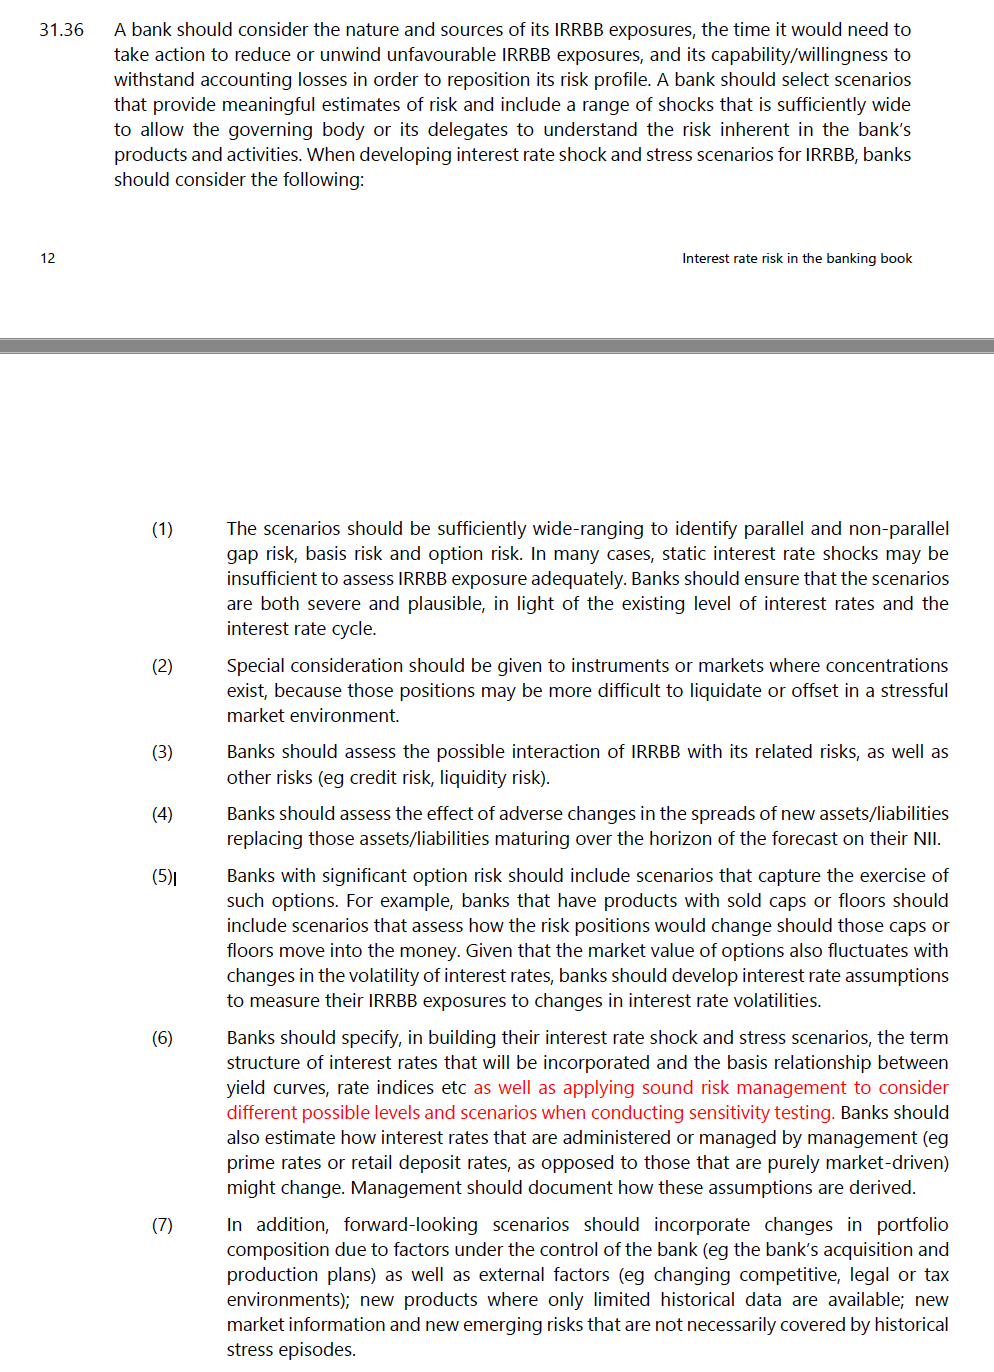

In [14]:
chunks[36].page_content #article 31.37, 31.38, 31.39

'31.37 \nFurther, banks should perform qualitative and quantitative reverse stress tests[6] in order to: \n(1) \nidentify interest rate scenarios that could severely threaten a bank’s capital and earnings; \nand  \n(2) \nreveal vulnerabilities arising from its hedging strategies and the potential behavioural \nreactions of its customers. \nFootnotes \n[6] \nSee the Principles of sound stress testing practices and supervision published by the \nCommittee in October 2018. \n<ins>31.38</ins> \n<ins>Sound risk management includes conducting stress tests on a regular basis and more frequently </ins>\n<ins>when warranted by market conditions, changes in the portfolio or increased interest rate risk </ins>\n<ins>exposure levels. </ins>\n<ins>31.39</ins> \n<ins>Changes in interest rates may impact the market value of a bank’s portfolio, including its </ins>\n<ins>embedded gains and losses.</ins><ins>7</ins><ins> Sound risk management includes holistically monitoring the impact </ins>\n<ins>on 

#### Observation
- Three different articles within the same chunk. **Note**: perhaps, the script is not robust to the red color of article number heading?

Exhibit of the updated regulations SRP31.37 to SRP31.39 is reported below:
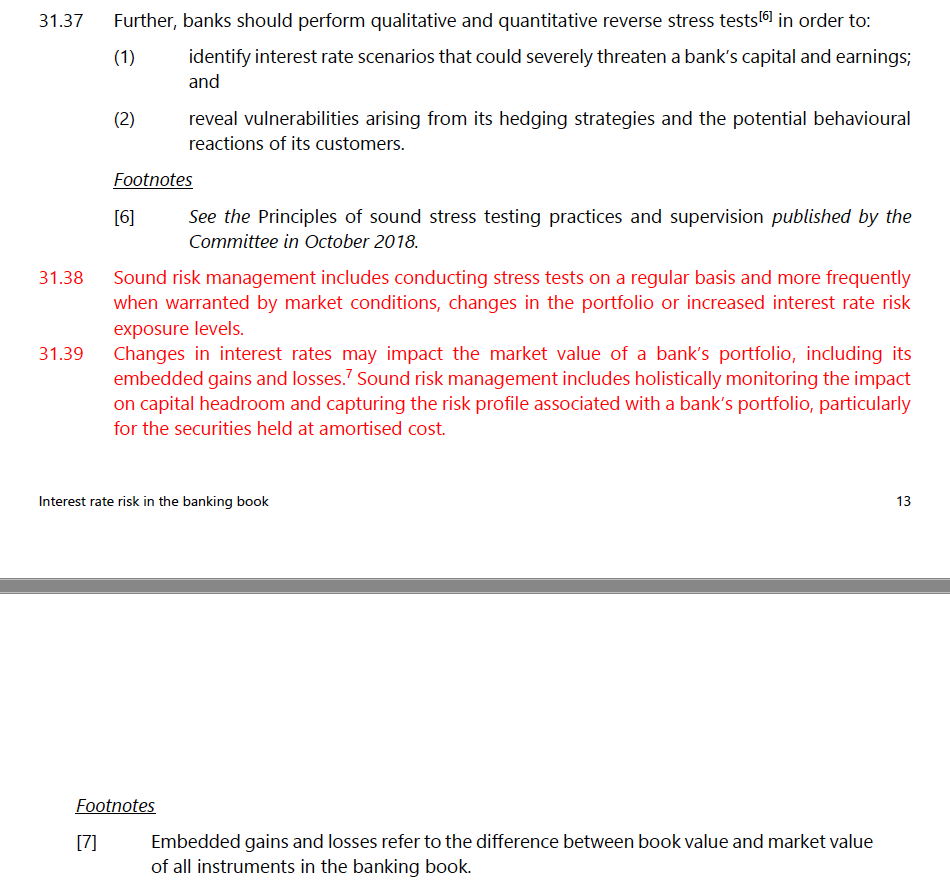

In [15]:
chunks[40].page_content #article 31.43; Behavioural considerations Table - with strikethroughs

'31.43 \nModelling assumptions should be conceptually sound and reasonable, and consistent with \nhistorical experience. Banks must carefully consider how the exercise of the behavioural \noptionality will vary not only under the interest rate shock and stress scenario but also across \nother dimensions, <ins>such as different markets, jurisdictions and products, and apply a prudent </ins>\n<ins>segmentation in modelling. Examples of modelling considerations related to data inputs and </ins>\n<del>components are set out in Table 1. For instance, considerations may include those set out in Table </del>\n<del>1.</del> \n<del>Considerations affecting behavioural optionality </del>\n<del>Table 1 </del>\n<del>Product </del>\n<del>Dimensions influencing the exercise of the embedded behavioural options </del>\n<del>Fixed rate loans subject to </del>\n<del>prepayment risk </del>\n<del>Loan size, loan-to-value ratio, borrower characteristics, contractual interest rates, </del>\n<del>seasoning, 

#### Observation
- Chunk correctly identifies the start and the end text of the article, as well as deletions and insertions.
- A markdown table may improve readability for human, but the chunked table text is equally understandable by LLM model.
- Try this prompt "reconstruct the two tables (the deletion of text in one table is made visible via strikethroughs; and the other table have all new wordings) from following text: {copy paste chunked text}"

Exhibit of the updated regulations SRP31.43 is reported below:
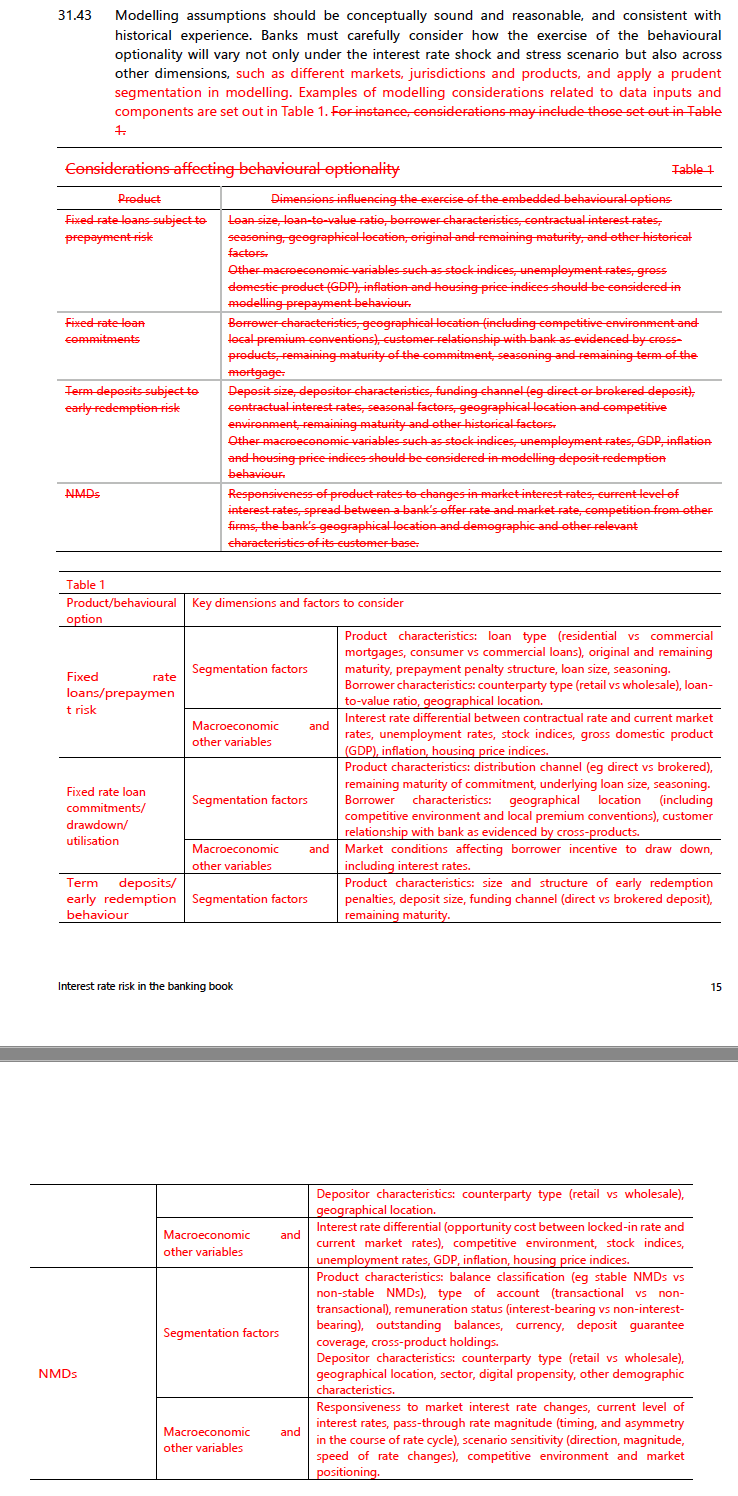


In [16]:
chunks[176].page_content #articles 98.29 to 98.35

'98.29 \nTo avoid the complexity of measuring total EV, banks typically therefore focus on measuring the \nlevel of change to the net present value of the relevant balance sheet items, based on existing or \nadjusted cash flows that are revalued in line with the interest rate shock and stress scenarios. The \nchange in the valuation is a measure of the level of IRRBB, and can be compared with the current \nvalue of equity to determine the change to the EVE. \n<ins>98.30</ins> \n<ins>The short- and medium-term earnings indicators and holistic earnings impact analysis in </ins>\n<ins>response to changing rates may include the following measures according to jurisdictional and </ins>\n<ins>firm-specific considerations: </ins>\n<ins>(1)</ins> \n<ins>Direct measures of short-term earnings risk arising from sudden interest rate </ins>\n<ins>movements such as (NII (shocked) – NII (baseline)) / Tier 1 capital, (NII (shocked) – NII </ins>\n<ins>(realised)) / NII (realised) and ΔNII / 3-year ave

#### Observation
- Different articles within the same chunk.
- **Note**: perhaps, the script is not robust to the red color of article number heading?

Exhibit of the updated regulations SRP98.29 to SRP98.35 is reported below:
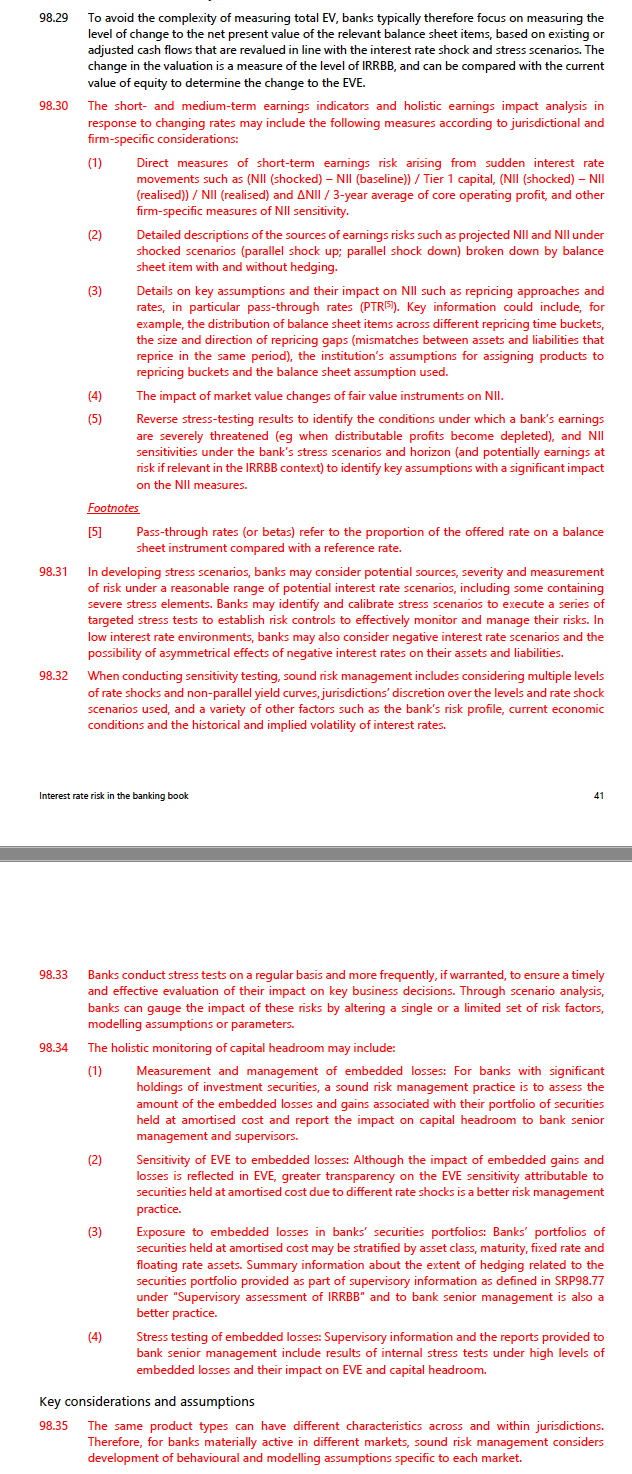

# Read the Knowledge Base (KB) regulation
- The KB is represented by the "Basel Framework", available at https://www.bis.org/committees/bcbs/basel-framework
- For convenience of this exercise, the KB is limited to the IRRBB scope. KB includes SRP31, SRP98, and DIS70.
- BCBS 368 and further pubblications (like 16th July 2024 "Recalibration of shocks for interest rate risk in the banking book) are integrated in the "Basel Framework"/KB

In [17]:
# KB file is placed in the same working directory of present notebook
kb_path = 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf' 

In [18]:
loader_kb = RedlinePDFLoader(kb_path)
kb = loader_kb.load()

print(kb[15].page_content,end="\n") 

08/11/2026
1024 / 1429
31.57
Model risk management for IRRBB measures should follow a holistic approach that begins with
motivation, development and implementation by model owners and users. Prior to receiving
authorisation for usage, the process for determining model inputs, assumptions, modelling
methodologies and outputs should be reviewed and validated independently of the
development of IRRBB models. The review and validation results and any recommendations on
model usage should be presented to and approved by the governing body or its delegates.
Upon approval, the model should be subject to ongoing review, process veriﬁcation and
validation at a frequency that is consistent with the level of model risk determined and
approved by the bank.
31.58
The ongoing validation process should establish a set of exception trigger events that obligate
the model reviewers to notify the governing body or its delegates in a timely fashion, in order
to determine corrective actions and/or restrict

#### No particular remarks for the KB extraction

Exhibit of "Basel Framework" from SRP31.57 to SRP31.62 is reported below:
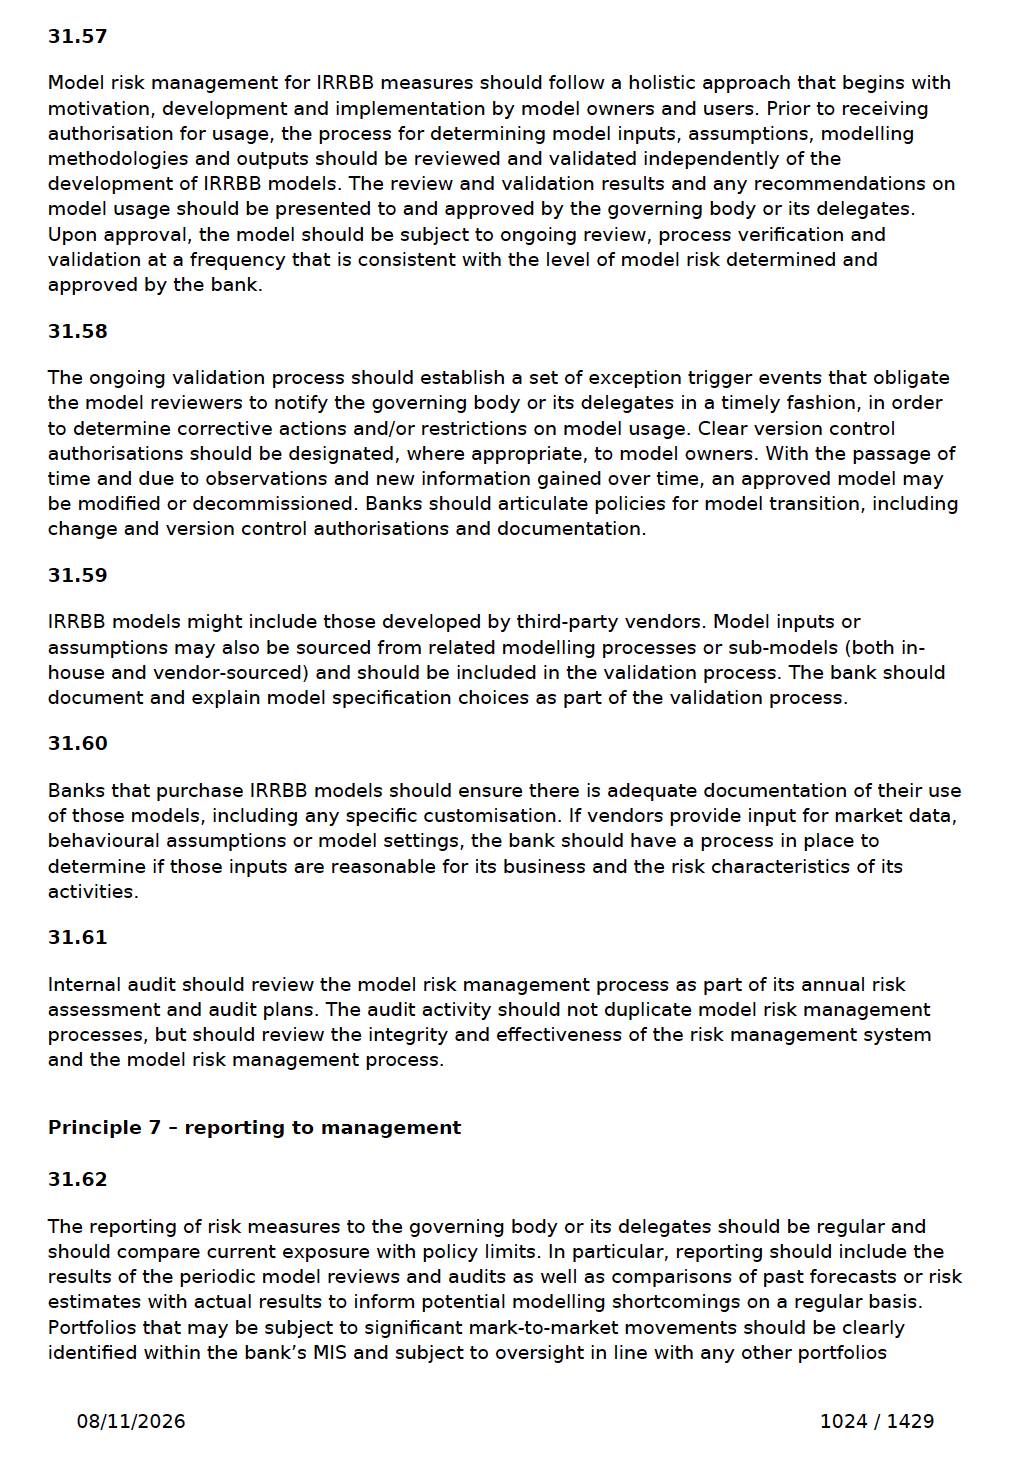

In [19]:
# Chunk KB
chunks_kb = chunk_by_article(kb)

In [20]:
chunks_kb[33]

Document(metadata={'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'total_pages': 56, 'article_id': '31.34', 'article_heading': '31.34', 'chunk_type': 'numbered_provision', 'chunk_index': 33, 'char_start': 24730, 'char_end': 25223}, page_content='31.34\nThe identiﬁcation of relevant shock and stress scenarios for IRRBB, the application of sound\nmodelling approaches and the appropriate use of the stress testing results require the\ncollaboration of diﬀerent experts within a bank (eg traders, the treasury department, the\nﬁnance department, the ALCO, the risk management and risk control departments and/or the\nbank’s economists). A stress-testing programme for IRRBB should ensure that the opinions of\nthe experts are taken into account.')

# Embedding
- In Retrieval Augmented Generation (RAG) systems the chunked documents are converted into **vector embeddings**, and stored in a database. When user asks a question, the system retrieves only the most relevant chunks.
- Vector embeddings convert chunks into lists of numbers (vectors) that capture chunk's underlying meaning and context. Placing items with similar meanings close together in a mathematical space allows AI models to quickly measure (dis)similarity and retrieve relevant information.

In [21]:
embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')

/var/folders/0_/p_pycfq9797_jqjlh9rhvwd80000gn/T/ipykernel_58788/4198310515.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')


In [22]:
embedding_1 = embedding_model.embed_query(chunks[33].page_content)
embedding_2 = embedding_model.embed_query(chunks[122].page_content)

In [23]:
print("Dimension of the embedding vector ",len(embedding_1))
len(embedding_1)==len(embedding_2)

Dimension of the embedding vector  1024


True

#### Observation
- The embedding model turns every chunk, whatever its length, into a vector of the same size (1,024 numbers).
- Because all vectors have the same size, we can compare them to find (dis)similar chunks.
- Identical vectors (chanks) between KB and new regulation -> not update
- Highly dissimilar vectors (chanks) between KB and new regulation -> totaly new regulatory provision
- Moderatly similar vectors (chanks) between KB and new regulation -> a new update/formulation of pre-existent regulation


## Vector database

In [24]:
out_dir = 'IRRBB_REG_db'

if not os.path.exists(out_dir):
  os.makedirs(out_dir)

In [25]:
vectorstore_kb = Chroma.from_documents(
    chunks_kb,
    embedding_model,
    persist_directory=out_dir
)

In [26]:
vectorstore_kb = Chroma(persist_directory=out_dir,embedding_function=embedding_model)

/var/folders/0_/p_pycfq9797_jqjlh9rhvwd80000gn/T/ipykernel_58788/1211554831.py:1: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore_kb = Chroma(persist_directory=out_dir,embedding_function=embedding_model)


In [27]:
# similarity_search against KB of SRP31.29 
# k=2, returns 2 most similar chunks
# text input is from updated SRP31.29
vectorstore_kb.similarity_search(" While the economic value and earnings-based measures share certain commonalities, the Committee observes that most commercial banks primarily utilise the latter for IRRBB management, whereas regulators tend to endorse the former as a benchmark for comparability and capital adequacy",
                                 k=2)

[Document(metadata={'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'total_pages': 56, 'article_id': '31.29', 'char_end': 22532, 'chunk_type': 'numbered_provision', 'article_heading': '31.29', 'char_start': 21924, 'chunk_index': 28}, page_content='31.29\nWhile the economic value and earnings-based measures share certain commonalities, the\nCommittee observes that most commercial banks primarily utilise the latter for IRRBB\nmanagement, whereas regulators tend to endorse the former as a benchmark for comparability\nand capital adequacy. The Committee acknowledges the importance of managing IRRBB\nthrough both economic value and earnings-based measures. If a bank solely minimises its\n\n08/11/2026\n1018 / 1429\neconomic value risk by matching the repricing of its assets with liabilities beyond the short\nterm, it could run the risk of earnings volatility.'),
 Document(metadata={'article_heading': '31.29', 'char_start': 21924, 'chunk_index': 28, 'source': 'basel-framework-IRRBB-S

#### Observations

- The wording from an updated SRP31.29 is the exact match with SRP31.29 from KB
- Now we'll compare the output by explicitly calling the chunked text: "chunks[28].page_content"

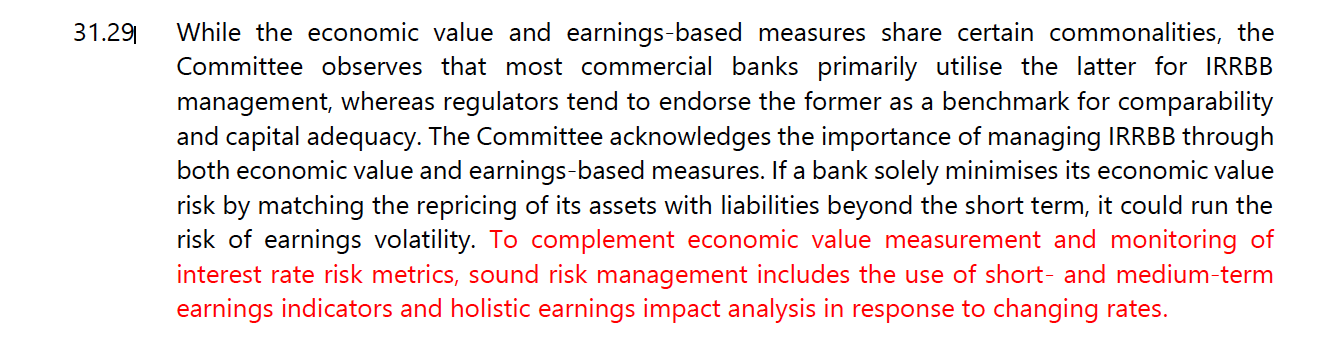

In [28]:
# similarity_search against KB of SRP31.29 
# call the chunks[28]
# k=1, returns 1 most similar chunks
print(vectorstore_kb.similarity_search(chunks[28].page_content,
                                 k=1))
print("")
print(chunks[28].page_content)

[Document(metadata={'char_end': 22532, 'article_heading': '31.29', 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'article_id': '31.29', 'char_start': 21924, 'chunk_type': 'numbered_provision', 'total_pages': 56, 'chunk_index': 28}, page_content='31.29\nWhile the economic value and earnings-based measures share certain commonalities, the\nCommittee observes that most commercial banks primarily utilise the latter for IRRBB\nmanagement, whereas regulators tend to endorse the former as a benchmark for comparability\nand capital adequacy. The Committee acknowledges the importance of managing IRRBB\nthrough both economic value and earnings-based measures. If a bank solely minimises its\n\n08/11/2026\n1018 / 1429\neconomic value risk by matching the repricing of its assets with liabilities beyond the short\nterm, it could run the risk of earnings volatility.')]

31.29 
While the economic value and earnings-based measures share certain commonalities, the 
Committee observes that mos

In [29]:
# similarity_search with score against KB of SRP31.29 
# same article number SRP31.29, but with new text in updated regulation.
# k=1, returns 1 most similar chunks
# similarity score = 0.03814823552966118 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[28].page_content,
                                 k=1))
print("")
print(chunks[28].page_content)

[(Document(metadata={'chunk_type': 'numbered_provision', 'total_pages': 56, 'char_end': 22532, 'chunk_index': 28, 'article_heading': '31.29', 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'char_start': 21924, 'article_id': '31.29'}, page_content='31.29\nWhile the economic value and earnings-based measures share certain commonalities, the\nCommittee observes that most commercial banks primarily utilise the latter for IRRBB\nmanagement, whereas regulators tend to endorse the former as a benchmark for comparability\nand capital adequacy. The Committee acknowledges the importance of managing IRRBB\nthrough both economic value and earnings-based measures. If a bank solely minimises its\n\n08/11/2026\n1018 / 1429\neconomic value risk by matching the repricing of its assets with liabilities beyond the short\nterm, it could run the risk of earnings volatility.'), 0.03814823552966118)]

31.29 
While the economic value and earnings-based measures share certain commonalities, the 
Comm

In [30]:
# similarity_search with score against KB of SRP31.27: chunks_kb[26]
# exactly thee same text with exactly the same artiicle number
# similarity score = 0.003043969627469778 (closer to 0 -> more similar)
# similarity score can be used as threshold to filter out simiilar/identical texts (no innovation)
print(vectorstore_kb.similarity_search_with_score(chunks[26].page_content,
                                 k=1))
print("")
print(chunks[26].page_content)

[(Document(metadata={'total_pages': 56, 'chunk_type': 'numbered_provision', 'chunk_index': 26, 'article_id': '31.27', 'char_start': 19821, 'char_end': 20205, 'article_heading': '31.27', 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf'}, page_content='31.27\nBanks’ internal measurement systems (IMS) should capture all material sources of IRRBB and\nassess the eﬀect of market changes on the scope of their activities. In addition to the impact of\nan interest rate shock on its economic value, a bank’s policy approach should take into account\nits ability to generate stable earnings suﬃcient to maintain its normal business operations.'), 0.003043969627469778)]

31.27 
Banks’ internal measurement systems (IMS) should capture all material sources of IRRBB and 
assess the effect of market changes on the scope of their activities. In addition to the impact of 
an interest rate shock on its economic value, a bank’s policy approach should take into account 
its ability to generate stable 

In [31]:
# Same text but different article: 31.58 (KB) vs 31.59 (update): chunks[56]
# New text in innovation not present in KB: 31.60 (update): chunks[56]
# similarity score = 0.05984719097614288 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[56].page_content,
                                 k=1))
print("")
print(chunks[56].page_content)

[(Document(metadata={'char_end': 41452, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'char_start': 40826, 'chunk_index': 57, 'article_heading': '31.58', 'total_pages': 56, 'article_id': '31.58', 'chunk_type': 'numbered_provision'}, page_content='31.58\nThe ongoing validation process should establish a set of exception trigger events that obligate\nthe model reviewers to notify the governing body or its delegates in a timely fashion, in order\nto determine corrective actions and/or restrictions on model usage. Clear version control\nauthorisations should be designated, where appropriate, to model owners. With the passage of\ntime and due to observations and new information gained over time, an approved model may\nbe modiﬁed or decommissioned. Banks should articulate policies for model transition, including\nchange and version control authorisations and documentation.'), 0.05984719097614288)]

31.59 
The ongoing validation process should establish a set of exception trigger e

In [32]:
# the strikethrough table with behavioural considerations: 31.42 (KB) vs 31.43 (update): chunks[40]
# similarity score = 0.03478580340743065 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[40].page_content,
                                 k=1))

print("")
print(chunks[40].page_content)

[(Document(metadata={'char_end': 34441, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'chunk_index': 41, 'chunk_type': 'numbered_provision', 'article_id': '31.42', 'total_pages': 56, 'char_start': 32477, 'article_heading': '31.42'}, page_content='31.42\nModelling assumptions should be conceptually sound and reasonable, and consistent with\nhistorical experience. Banks must carefully consider how the exercise of the behavioural\noptionality will vary not only under the interest rate shock and stress scenario but also across\nother dimensions. For instance, considerations may include those set out in Table 1.\nConsiderations aﬀecting behavioural optionality\nTable 1\nProduct\nDimensions inﬂuencing the exercise of the embedded behavioural\noptions\nFixed rate loans\nsubject to\nprepayment risk\nLoan size, loan-to-value ratio, borrower characteristics, contractual\ninterest rates, seasoning, geographical location, original and\nremaining maturity, and other historical factors.\n

In [33]:
#text with innovations and different article number: 31.66 (KB) vs 31.69 (update): chunks[65]
# similarity score = 0.0568942129611969 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[65].page_content,
                                 k=1))

print("")
print(chunks[65].page_content)

[(Document(metadata={'char_end': 45646, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'article_heading': '31.66', 'chunk_type': 'numbered_provision', 'total_pages': 56, 'chunk_index': 65, 'article_id': '31.66', 'char_start': 45127}, page_content='31.66\nBanks are responsible for evaluating the level of capital that they should hold, and for ensuring\nthat this is suﬃcient to cover IRRBB and its related risks. The contribution of IRRBB to the\noverall internal capital assessment should be based on the bank’s IMS outputs, taking account\nof key assumptions and risk limits. The overall level of capital should be commensurate with\nboth the bank’s actual measured level of risk (including for IRRBB) and its risk appetite, and be\nduly documented in its ICAAP report.'), 0.0568942129611969)]

31.69 
Banks are responsible for evaluating the level of capital that they should hold, and for ensuring 
that this is sufficient to cover IRRBB and its related risks <ins>through holistic mon

In [34]:
#exactly same text but with different article number and regul. referernces: 31.76 (KB) vs 31.79 (update): chunks[75]
# similarity score = 0.006695103831589222 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[75].page_content,
                                 k=1))

print("")
print(chunks[75].page_content)

[(Document(metadata={'article_heading': '31.76', 'chunk_type': 'numbered_provision', 'char_end': 51038, 'total_pages': 56, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'chunk_index': 75, 'article_id': '31.76', 'char_start': 50440}, page_content='31.76\nSupervisors should review regularly the outputs from the bank’s IMS, including the bank’s\nIRRBB exposures (both economic value and earnings-based measures) based on the internal\ncalculations using at least the prescribed interest rate shock scenarios speciﬁed in SRP31.90 to\nSRP31.93, as well as any additional interest rate shock and stress scenarios they determine\nshould be assessed. Supervisors may also form their evaluation of a bank’s IMS by applying\nsupervisory estimates which they have developed. Supervisors should also review the\ninformation disclosed by banks under Principle 8.'), 0.006695103831589222)]

31.79 
Supervisors should review regularly the outputs from the bank’s IMS, including the bank’s IRRBB 
exposu

In [35]:
# new article that is not present in KB: 'none' (KB) vs 31.81 (update): chunks[77]
# similarity score = 0.11912171542644501 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[77].page_content,
                                 k=1))

print("")
print(chunks[77].page_content)

[(Document(metadata={'chunk_index': 78, 'total_pages': 56, 'chunk_type': 'numbered_provision', 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'article_id': '31.79', 'char_start': 52829, 'char_end': 53318, 'article_heading': '31.79'}, page_content='31.79\nThe supervisory evaluation should be undertaken both on a standalone basis and by making\ncomparisons with peer banks – in particular, supervisors should compare the key behavioural\nand strategic assumptions being made by banks within their jurisdictions, to determine\nwhether they can be justiﬁed with regard to the economic environment and business model.\nSupervisors should ensure that the information they review is comparable and consistent\nacross the banks that they supervise.'), 0.11912171542644501)]

31.81 
<ins>For peer comparisons, supervisors evaluate a bank’s quantitative and qualitative information </ins>
<ins>against that of the identified peer group, taking particular risk factors into account during the </ins>

In [36]:
# same text and same article: 98.29 (KB) vs 98.29 (update): chunks[77]
# 98.30 to 98.35 are completely new, with no match in KB: chunks[77]
# similarity score = 0.09343511611223221 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[176].page_content,
                                 k=1))

print("")
print(chunks[176].page_content)

[(Document(metadata={'char_start': 108250, 'article_heading': '98.29', 'char_end': 108735, 'chunk_index': 170, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'total_pages': 56, 'chunk_type': 'numbered_provision', 'article_id': '98.29'}, page_content='98.29\nTo avoid the complexity of measuring total EV, banks typically therefore focus on measuring\nthe level of change to the net present value of the relevant balance sheet items, based on\nexisting or adjusted cash ﬂows that are revalued in line with the interest rate shock and stress\nscenarios. The change in the valuation is a measure of the level of IRRBB, and can be\ncompared with the current value of equity to determine the change to the EVE.\nKey considerations and assumptions'), 0.09343511611223221)]

98.29 
To avoid the complexity of measuring total EV, banks typically therefore focus on measuring the 
level of change to the net present value of the relevant balance sheet items, based on existing or 
adjusted cash flow

In [37]:
# new articles in reg.update: 'none' (KB) vs 98.74 to 98.80 (update): chunks[213]
# similarity score = 0.07125764340162277 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[213].page_content,
                                 k=1))

print("")
print(chunks[213].page_content)

[(Document(metadata={'chunk_index': 204, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'total_pages': 56, 'article_heading': '98.63', 'char_start': 130098, 'chunk_type': 'numbered_provision', 'article_id': '98.63', 'char_end': 130815}, page_content='98.63\nSupervisors may, applying national discretion, set a higher ﬂoor under the local interest rate\nshock scenarios for their home currency, or a higher cap, resulting in more conservative\nshocks. Supervisors may also, applying national discretion, set a zero or negative lower bound\nfor the post-shock interest rates \n where j represents the six interest rate shock scenarios\nset out in SRP31.91.\n\n08/11/2026\n1298 / 1429\nDIS70\n<ins>Interest rate risk in the</ins>\n<ins>banking book</ins>\nThis chapter describes disclosure requirements\nfor interest rate risk in the banking book.\nVersion eﬀective as of 15\nDecember 2019\nFirst version in the format of the consolidated\nframework.\n\n08/11/2026\n1299 / 1429\nIntroduction'

In [38]:
# same article same text: 98.2 (KB) vs 98.2 (update): chunks[149]
# similarity score = 0.016502028331160545 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[149].page_content,
                                 k=1))

print("")
print(chunks[149].page_content)

[(Document(metadata={'char_start': 88872, 'chunk_type': 'numbered_provision', 'article_id': '98.2', 'article_heading': '98.2', 'chunk_index': 143, 'char_end': 89469, 'total_pages': 56, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf'}, page_content='98.2\nExcessive IRRBB can pose a signiﬁcant threat to a bank’s current capital base or future\nearnings if not managed appropriately. Changes in interest rates can aﬀect the underlying\neconomic value of the bank’s assets, liabilities and oﬀ-balance sheet instruments, because the\npresent value of future cash ﬂows (and, in many cases, the amounts of cash ﬂows themselves)\nchange when interest rates change. Changes in interest rates also aﬀect a bank’s earnings by\nincreasing or decreasing its net interest income (NII) and the level of other interest rate-\nsensitive income and operating expenses.'), 0.016502028331160545)]

98.2 
Excessive IRRBB can pose a significant threat to a bank’s current capital base or future earnings 
if not 

In [39]:
# same article, deleted text: 31.35 (KB) vs 31.35 (update): chunks[34]
# similarity score = 0.022035252302885056 (closer to 0 -> more similar)
print(vectorstore_kb.similarity_search_with_score(chunks[34].page_content,
                                 k=1))

print("")
print(chunks[34].page_content)

[(Document(metadata={'char_end': 25958, 'article_heading': '31.35', 'total_pages': 56, 'chunk_index': 34, 'chunk_type': 'numbered_provision', 'char_start': 25223, 'article_id': '31.35', 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf'}, page_content='31.35\n\n08/11/2026\n1019 / 1429\nBanks should determine, by currency, a range of potential interest rate movements against\nwhich they will measure their IRRBB exposures. Management should ensure that risk is\nmeasured under a reasonable range of potential interest rate scenarios, including some\ncontaining severe stress elements. In developing the scenarios, banks should consider a\nvariety of factors, such as the shape and level of the current term structure of interest rates\nand the historical and implied volatility of interest rates. In low interest rate environments,\nbanks should also consider negative interest rate scenarios and the possibility of asymmetrical\neﬀects of negative interest rates on their assets and liabiliti

#### Summary table

| KB | New | Description | Similarity score |
|---|---|---|---|
| \(31.35\) | \(31.35\) | Same article number; text deleted in the update. | 0.022035252302885056 |
| \(98.2\) | \(98.2\) | Same article number and identical text. | 0.016502028331160545 |
| — | \(98.74\)–\(98.80\) | Completely new articles, absent in KB. | 0.07125764340162277 |
| \(98.29\) | \(98.29\) | Same article number and identical text. | 0.09343511611223221 |
| — | \(98.30\)–\(98.35\) | Completely new provisions without a KB match; identified in the same chunk as 98.29. | 0.09343511611223221 |
| — | \(31.81\) | New article absent in KB. | 0.11912171542644501 |
| \(31.76\) | \(31.79\) | Identical text, but different article numbering and regulatory references. | 0.006695103831589222 |
| \(31.66\) | \(31.69\) | Renumbered article with substantive additions and modifications. | 0.0568942129611969 |
| \(31.42\) | \(31.43\) | Updated table with strikethrough text and behavioural considerations. | 0.03478580340743065 |
| \(31.58\) | \(31.59\) | Identical text with a different article number. | 0.05984719097614288 |
| — | \(31.60\) | New text absent from the KB; identified in the same chunk as 31.59. | 0.05984719097614288 |
| \(31.27\) | \(31.27\) | Identical article number and text. | 0.003043969627469778 |
| \(31.29\) | \(31.29\) | Same article number, but updated regulation introduces new text. | 0.03814823552966118 |


* The similarity score acts as a filter in separating innovation text against the rest
* In what follows we loop all the New chunks against their similar counterparties in KB
* **A preliminary analysis suggest a similarity distance threshold of 0.016503**

In [40]:
import numpy as np
import pandas as pd

K = 1   # KB matches per new chunk (use K = 1 if you only want the best one)

rows = []
for i, chunk in enumerate(chunks):                       # chunks = new document
    results = vectorstore_kb.similarity_search_with_score(chunk.page_content, k=K)
    for rank, (kb_doc, distance) in enumerate(results, start=1):
        rows.append({
            "new_idx":  i,
            "new_meta": chunk.metadata,
            "new_text": chunk.page_content,
            "rank":     rank,
            "kb_meta":  kb_doc.metadata,
            "kb_text":  kb_doc.page_content,
            "distance": distance,                        # raw Chroma score: LOWER = more similar
        })
matches_df = pd.DataFrame(rows)

In [41]:
matches_df = matches_df.sort_values("distance", ascending=False).reset_index(drop=True)
matches_df.head(20)

,new_idx,new_meta,new_text,rank,kb_meta,kb_text,distance
0,210,{'source': /Users/dima/interest-rate-risk-bank...,"99.9\n,\ni c\ni c\nS\nP\nR\nt",1,{'source': 'basel-framework-IRRBB-SRP31-SRP98-...,0.8,0.336932
1,92,{'source': /Users/dima/interest-rate-risk-bank...,0.65,1,{'source': 'basel-framework-IRRBB-SRP31-SRP98-...,0.8,0.240161
2,60,{'source': /Users/dima/interest-rate-risk-bank...,31.64 \n<ins>Sound risk management includes go...,1,"{'char_end': 52426, 'char_start': 51038, 'arti...",31.77\n\n08/11/2026\n1028 / 1429\nWhen reviewi...,0.208680
3,95,{'source': /Users/dima/interest-rate-risk-bank...,0.6\nflattener c\nk\nshort c\nk\nlong c\nk\nS\...,1,{'source': 'basel-framework-IRRBB-SRP31-SRP98-...,"31.91\nGiven Table 2, the instantaneous shocks...",0.164894
4,182,{'source': /Users/dima/interest-rate-risk-bank...,98.41 \nBehavioural option positions require m...,1,"{'chunk_type': 'numbered_provision', 'article_...",31.42\nModelling assumptions should be concept...,0.155780
5,93,{'source': /Users/dima/interest-rate-risk-bank...,0.9\nsteepener c\nk\nshort c\nk\nlong c\nk\nS\...,1,"{'chunk_index': 133, 'chunk_type': 'numbered_p...",0.8\n3\nSteepener,0.151545
6,179,{'source': /Users/dima/interest-rate-risk-bank...,98.38 \nBehaviour of option positions is one o...,1,"{'char_start': 110155, 'char_end': 110570, 'so...",98.32\nBehaviour of option positions is one of...,0.151474
7,77,{'source': /Users/dima/interest-rate-risk-bank...,"31.81 \n<ins>For peer comparisons, supervisors...",1,"{'char_end': 53318, 'article_id': '31.79', 'to...",31.79\nThe supervisory evaluation should be un...,0.119122
8,180,{'source': /Users/dima/interest-rate-risk-bank...,98.39 \nThe approach taken by banks generally ...,1,"{'article_id': '98.32', 'total_pages': 56, 'ch...",98.32\nBehaviour of option positions is one of...,0.095942
9,176,{'source': /Users/dima/interest-rate-risk-bank...,98.29 \nTo avoid the complexity of measuring t...,1,{'source': 'basel-framework-IRRBB-SRP31-SRP98-...,98.29\nTo avoid the complexity of measuring to...,0.093435


In [42]:
#check chunks[92, 95], 
#some noise data with "article_heading" capturing shock size / multiplicative factors rather than the true article number
#exclude
print(vectorstore_kb.similarity_search_with_score(chunks[92].page_content,
                                 k=1))

print("")
print(chunks[92].page_content)

print("")
print("")

print(vectorstore_kb.similarity_search_with_score(chunks[95].page_content,
                                 k=1))

print("")
print(chunks[95].page_content)

[(Document(metadata={'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'char_start': 82094, 'article_id': '0.8', 'total_pages': 56, 'char_end': 82106, 'chunk_index': 137, 'article_heading': '0.8', 'chunk_type': 'numbered_provision'}, page_content='0.8'), 0.24016137421131134)]

0.65


[(Document(metadata={'chunk_index': 90, 'article_heading': '31.91', 'char_start': 60324, 'char_end': 61845, 'article_id': '31.91', 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'chunk_type': 'numbered_provision', 'total_pages': 56}, page_content='31.91\nGiven Table 2, the instantaneous shocks to the risk-free rate for parallel, short and long, for\neach currency, the following parameterisations of the six interest rate shock scenarios should\nbe applied:\nParallel shock for currency c: a constant parallel shock up or down across all time\n1.\nbuckets. \nShort rate shock for currency c: shock up or down that is greatest at the shortest tenor\n2.\nmidpoint. That shock, through the shaping s

In [43]:
#exclude pairs with conflicting starting numbers (the new 31.25 chunk is paired with 98.33 KB).

lead = r"^\s*(\d+)"          # we always have numbers at the start of the text (31 in "31.21 ...")


matches_df["new_lead"] = matches_df["new_text"].str.extract(lead)[0]
matches_df["kb_lead"]  = matches_df["kb_text"].str.extract(lead)[0]

both = matches_df["new_lead"].notna() & matches_df["kb_lead"].notna()

diff_df    = matches_df[both & (matches_df["new_lead"] != matches_df["kb_lead"])]   # e.g. 31 vs 98
no_lead_df = matches_df[~both]                                                       # a text with no leading number

diff_df[["new_idx", "rank", "distance", "new_lead", "kb_lead", "new_text", "kb_text"]]

,new_idx,rank,distance,new_lead,kb_lead,new_text,kb_text
0,210,1,0.336932,99,0,"99.9\n,\ni c\ni c\nS\nP\nR\nt",0.8
3,95,1,0.164894,0,31,0.6\nflattener c\nk\nshort c\nk\nlong c\nk\nS\...,"31.91\nGiven Table 2, the instantaneous shocks..."
4,182,1,0.155780,98,31,98.41 \nBehavioural option positions require m...,31.42\nModelling assumptions should be concept...
11,97,1,0.070459,3,31,3.5\n4\nshort\nkt\ne\n= 0.417. Banks would mul...,31.92\nThe following examples illustrate the s...


In [44]:
matches_new_df = matches_df.copy()        

both     = matches_new_df["new_lead"].notna() & matches_new_df["kb_lead"].notna()
mismatch = both & (matches_new_df["new_lead"] != matches_new_df["kb_lead"])

matches_new_df = matches_new_df[~mismatch].reset_index(drop=True)
print(f"Removed {mismatch.sum()} rows, {len(matches_new_df)} remain")


Removed 4 rows, 210 remain


In [45]:
#filter for distance>0.016503
matches_filt_df = matches_new_df[matches_new_df["distance"] > 0.016503].reset_index(drop=True)
print(f"{len(matches_filt_df)} of {len(matches_new_df)} rows kept")

82 of 210 rows kept


In [46]:
matches_filt_df = matches_filt_df.sort_values("distance", ascending=True).reset_index(drop=True)
matches_filt_df.head(60)

,new_idx,new_meta,new_text,rank,kb_meta,kb_text,distance,new_lead,kb_lead
0,41,{'source': /Users/dima/interest-rate-risk-bank...,"31.44 \nIn addition, banks with positions deno...",1,"{'article_heading': '31.43', 'chunk_index': 42...","31.43\n\n08/11/2026\n1022 / 1429\nIn addition,...",0.016855,31,31
1,63,{'source': /Users/dima/interest-rate-risk-bank...,31.67 \nReports detailing the bank’s IRRBB exp...,1,"{'char_end': 44980, 'source': 'basel-framework...",31.64\nReports detailing the bank’s IRRBB expo...,0.016974,31,31
2,123,{'source': /Users/dima/interest-rate-risk-bank...,"31.121 Prepayments, or parts thereof, for whic...",1,"{'chunk_type': 'numbered_provision', 'char_sta...","31.117\nPrepayments, or parts thereof, for whi...",0.017021,31,31
3,61,{'source': /Users/dima/interest-rate-risk-bank...,31.65 \nThe reporting of risk measures to the ...,1,"{'chunk_type': 'numbered_provision', 'char_sta...",31.62\nThe reporting of risk measures to the g...,0.017052,31,31
4,70,{'source': /Users/dima/interest-rate-risk-bank...,"31.74 \nSupervisors should, on a regular basis...",1,"{'article_heading': '31.71', 'chunk_index': 70...","31.71\nSupervisors should, on a regular basis,...",0.017663,31,31
5,181,{'source': /Users/dima/interest-rate-risk-bank...,98.40 \nAutomatic option positions can therefo...,1,"{'article_id': '98.33', 'total_pages': 56, 'ch...",98.33\nAutomatic option positions can therefor...,0.017837,98,98
6,111,{'source': /Users/dima/interest-rate-risk-bank...,31.110 Positions not amenable to standardisati...,1,"{'chunk_index': 105, 'char_end': 72497, 'total...",31.106\nPositions not amenable to standardisat...,0.017970,31,31
7,177,{'source': /Users/dima/interest-rate-risk-bank...,98.36 \nBoth measures of IRRBB are significant...,1,{'source': 'basel-framework-IRRBB-SRP31-SRP98-...,98.30\nBoth measures of IRRBB are signiﬁcantly...,0.017972,98,98
8,147,{'source': /Users/dima/interest-rate-risk-bank...,"31.133 First, the loss in economic value of eq...",1,"{'chunk_index': 141, 'source': 'basel-framewor...","31.129\nFirst, the loss in economic value of e...",0.018078,31,31
9,67,{'source': /Users/dima/interest-rate-risk-bank...,31.71 \nCapital adequacy for IRBBB should be c...,1,"{'article_heading': '31.68', 'char_end': 46319...",31.68\nCapital adequacy for IRBBB should be co...,0.018079,31,31


In [47]:
#perfect identity text (position 19, chunks[108])
print(vectorstore_kb.similarity_search_with_score(chunks[108].page_content,
                                 k=1))

print("")
print(chunks[108].page_content)

print("")
print("")
print("")

#perfect identity text (position 39, chunks[72])
print(vectorstore_kb.similarity_search_with_score(chunks[72].page_content,
                                 k=1))

print("")
print(chunks[72].page_content)

print("")
print("")
print("")

#perfect identity text (position 59, chunks[196])
print(vectorstore_kb.similarity_search_with_score(chunks[196].page_content,
                                 k=1))

print("")
print(chunks[196].page_content)

print("")
print("")
print("")

# Updated behavioural assumptions Table  (position 54, chunks[40])
# Similar distance measure of a perfectly identical text
print(vectorstore_kb.similarity_search_with_score(chunks[40].page_content,
                                 k=1))

print("")
print(chunks[40].page_content)



[(Document(metadata={'total_pages': 56, 'article_id': '31.103', 'char_start': 69266, 'article_heading': '31.103', 'char_end': 70351, 'source': 'basel-framework-IRRBB-SRP31-SRP98-DIS70.pdf', 'chunk_index': 102, 'chunk_type': 'numbered_provision'}, page_content='31.103\nNotional repricing cash ﬂows can be slotted into appropriate time buckets or time bucket\nmidpoints based on their contractual maturity, if subject to ﬁxed coupons, or into the next\nrepricing period if coupons are ﬂoating. Positions amenable to standardisation fall into two\ncategories:\nFixed rate positions: such positions generate cash ﬂows that are certain till the point of\n1.\ncontractual maturity. Examples are ﬁxed rate loans without embedded prepayment\noptions, term deposits without redemption risk and other amortising products such as\nmortgage loans. All coupon cash ﬂows and periodic or ﬁnal principal repayments should\nbe allocated to the time bucket midpoints closest to the contractual maturity.\nFloating rat

#### Observations

- Distance metric appears to give misleading information about (dis)similarity of the text pairs
- For example chunks[196] has 0.0398 distance measure, while the distance for chunks[40] is 0.0347. But in the former the two articles are exactly the same (98.57 new vs 98.47 KB), while chunks[40] represents the updated Table with behavioural assumptions (31.43 new vs 31.42 KB).
- We decide to retain 0.016503 threshold, but LLM prompt must explicitly account for scenarios with extremely similar pairs and to not rely solely on the distance measure
- Alternave formulations of distance measure should also be explored

# LLM model

In [48]:
# 1. INITIALIZE LLM and DATA PREPARATION (Keep ONLY 'new_text' and 'kb_text')
# =====================================================================
from concurrent.futures import ThreadPoolExecutor
# Load OpenAI credentials from config.json
# config.json is expected to be in the same working directory of this notebook and looks like:
# {"OPENAI_API_KEY": "your-sk____-key", "OPENAI_API_BASE": "https://api.openai.com/v1"}
with open("config.json", "r") as f:   
    config = json.load(f)

# Initializing the OpenAI client
client = OpenAI(api_key=config["OPENAI_API_KEY"], base_url=config["OPENAI_API_BASE"])
MODEL_NAME = "gpt-6-luna"

def prepare_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    # Drop all other columns, keeping strictly new_text and kb_text
    return df[["new_text", "kb_text"]].dropna().reset_index(drop=True)

In [49]:
# 2. AGENT 1: ROW-LEVEL ANALYST (System Prompt, Guardrails & 2-Sided Input)
# =====================================================================
REG_SYSTEM_PROMPT = """You are a Seasoned Regulatory Expert specialized in banking frameworks.

### EXPECTATIONS & GOAL
You have to compare a newly updated regulatory clause (NEW_TEXT) against an existing Knowledge Base clause (KB_TEXT) and return a structured JSON evaluation of whether a substantive regulatory change occurred.

### INSTRUCTIONS
1. **Interpret Tags in NEW_TEXT**: 
- `<ins>` marks the start of newly inserted text and `</ins>` marks the end of the insertion. 
- `<del>` marks the start of deleted text (text removed from KB_TEXT), and `</del>` marks the end of the deletion.
- `\n` marks the start of the text in the next line. `\n` is also present in KB_TEXT
- Unmarked text outside these tags represents unchanged baseline text.
2. **Extract Article References**: Identify the article or section numbers directly from the start of NEW_TEXT and KB_TEXT (e.g., "31.44", "98.40").
3. **Compare Substantive Meaning**: Compare obligations, scope, definitions, quantitative thresholds, formulas, and reporting requirements.
4. **Ignore Renumbering & Formatting Noise**: Regulatory updates frequently shift article numbers (e.g., 31.43 becoming 31.44) or strip date stamps (e.g., "08/11/2026"). Ignore 'Footnotes'. If the underlying rule has not changed, set "has_change" to false.
5. **Detect Brand-New Provisions**: If KB_TEXT covers a completely unrelated topic, set "has_change" to true, set "kb_article_ref" to "None", and note that this is a brand-new requirement.
6. **Write Crisp Summaries**: When "has_change" is true, write a concise 1-2 sentence plain-English summary stating precisely what was added, removed, or modified.

### GUARDRAILS
- **Strict Grounding**: Please rely EXCLUSIVELY on the provided NEW_TEXT and KB_TEXT. Do not assume intent or bring in external knowledge.
- **Text Tags Fidelitye**: Treat `<del>...</del>` strictly as repealed/removed content. Never report deleted text as an active requirement in the new regulation.
- **No Raw Markup in Output**: Never include `<ins>`, `</ins>`, `<del>`, `</del>` or `\n` tags inside your `change_summary` or article reference fields.
- **Zero Hallucination**: Never invent article numbers, dates, or obligations not explicitly written in the text. If the answer cannot be provided in by the context, flag "has_change" as true and ask for human revision in "change_summary" 
- **No False Positives**: Never flag punctuation, whitespace, capitalization, or pure article renumbering as a substantive change.

### REQUIRED JSON OUTPUT FORMAT
Respond strictly with a valid JSON object matching these exact keys:
{
  "new_article_ref": "string",
  "kb_article_ref": "string",
  "has_change": boolean,
  "change_summary": "string (empty string if has_change is false)"
}"""

def build_comparison_user_prompt(new_text: str, kb_text: str) -> str:
    return f"""Compare the following two regulatory extracts:

<NEW_TEXT>
{new_text}
</NEW_TEXT>

<KB_TEXT>
{kb_text}
</KB_TEXT>"""

def analyze_single_row(row_tuple) -> dict:
    idx, row = row_tuple
    user_prompt = build_comparison_user_prompt(row["new_text"], row["kb_text"])
    
    response = client.chat.completions.create(
        model=MODEL_NAME,
        temperature=1, #1 is required by "gpt-6-luna" model; consider using other models allowing 0.0-0.1 (more stable and "grounded" output)
        max_completion_tokens=2048,
        response_format={"type": "json_object"},
        messages=[
            {"role": "system", "content": REG_SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt}
        ]
    )
    
    raw_content = response.choices[0].message.content
    parsed = json.loads(raw_content)
    parsed["row_index"] = idx
    return parsed


In [50]:
# 3. AGENT 2: NEWSLETTER EDITOR
# =====================================================================

EDITOR_SYSTEM_PROMPT = """You are a Senior Banking Regulation Specialist writing an insightful, practitioner-focused executive newsletter post.

### EXPECTATIONS & GOAL
Your objective is to synthesize verified row-level regulatory changes into a crisp, high-impact commentary post that mirrors the exact structure, numbered format, tone, and pacing of HUMAN_TEMPLATE, while grounding every regulatory claim in VERIFIED_CHANGES and citing exact article references.

### INSTRUCTIONS
1. **Mirror the Template's Exact Structure & Numbering**:
   - **Opening Hook**: Start with a clear 2-sentence announcement of the publication/consultation (including comment deadline if applicable).
   - **Item 1 (`1) Tip:`) & Scope Framing**: Follow with `1) Tip:` and a short framing paragraph explaining what stays unchanged versus the core shift of the proposal.
   - **Numbered Thematic Takeaways (`2)` through `6)`+)**: Group the verified regulatory changes into numbered takeaways (`2)`, `3)`, `4)`, etc.). Start each numbered point with a **bold punchy headline sentence**, followed by 2-3 short, plain-English sentences explaining the practical requirement.
   - **Closing Practitioner Takeaway**: End with a sharp `Personal take:` paragraph summarizing the real operational burden for banks, followed by a punchy closing line.
2. **Cite Exact Article References**: Integrate the exact article numbers from VERIFIED_CHANGES (e.g., `(Art. 31.44, formerly 31.43)` or `(Art. 98.40)`) cleanly inside each numbered takeaway so readers can trace every point back to the text.
3. **Consolidate & Prioritize**: Group related row-level changes under cohesive numbered points and focus on the most substantive shifts rather than listing every minor row separately.

### GUARDRAILS
- **Strict Fact Grounding**: Every regulatory change, metric, or requirement mentioned MUST come exclusively from VERIFIED_CHANGES (and static framing details explicitly present in HUMAN_TEMPLATE when analyzing this document). Do NOT invent new rules or metrics.
- **No Emojis or Raw Markup**: Do not add emojis, and ensure zero `<ins>` or `<del>` tags appear anywhere in the output.
- **Empty State Handling**: If VERIFIED_CHANGES states no substantive changes were detected, clearly report that no material edits were found rather than fabricating takeaways."""


def generate_newsletter(analyzed_df: pd.DataFrame) -> str:
    changes_df = analyzed_df[analyzed_df["has_change"] == True]
    
    if changes_df.empty:
        verified_changes_text = "No substantive regulatory changes were detected across any rows."
    else:
        lines = []
        for _, r in changes_df.iterrows():
            lines.append(
                f"- New Article: {r['new_article_ref']} "
                f"(Prior KB Article: {r['kb_article_ref']}) -> {r['change_summary']}"
            )
        verified_changes_text = "\n".join(lines)

    user_prompt = f"""Write the final newsletter post following the exact style, numbered structure, and tone of the template below, populated with the verified regulatory changes and their article references:

<HUMAN_TEMPLATE>
The Basel Committee has published its consultation on additional Pillar 2 guidance for interest rate risk in the banking book. Comments are open until 9 February 2027.
1) Tip: in the annex, the proposed edits to SRP31 and SRP98 are marked in red, so it’s quick to see what’s actually new.
The first thing to notice is what does not change. The six shock scenarios, the 15% Tier 1 outlier test and the standardised framework all stay as they are. There is no new capital charge.
The proposal is about how well banks manage IRRBB, not how they calculate it. Here is what I see as most important:
2) Non-maturity deposits move to centre stage. Banks are expected to segment deposits based on evidence: insured vs uninsured, balance size, account type, pass-through behaviour and even “digital propensity”. Historical data should not be extrapolated mechanically. The Committee also says banks should not rely solely on the standardised core-deposit caps, as they “may be insufficiently conservative”.
3) Backtesting becomes an expectation. NMD forecasts, prepayment models and deposit pricing should be backtested, with thresholds that trigger a review. Every change to an assumption should be justified, including management overlays and floors on rate shocks.
4) Embedded losses are now explicitly in scope. Banks with large bond portfolios at amortised cost should measure their unrealised losses, project them under rate shocks and report the impact on capital headroom. This is a clear lesson from 2023.
5) NII alongside EVE. New earnings indicators, such as ΔNII / Tier 1 and ΔNII / 3-year average core operating profit, address what the long-horizon outlier test can hide: the short- and medium-term impact on earnings.
6) Supervisors will compare banks with their peers. Your NMD assumptions, duration gap and hedging strategy may soon be compared directly with those of banks in the same competitive market.
Personal take: for banks that are already IRRBB-compliant, the real work is not new calculations. It is the evidence behind the behavioural assumptions, the data on embedded losses, and showing that ALCO acts on what the models say.
Many banks will find their deposit models harder to defend than their EVE numbers
</HUMAN_TEMPLATE>

<VERIFIED_CHANGES>
{verified_changes_text}
</VERIFIED_CHANGES>"""

    response = client.chat.completions.create(
        model=MODEL_NAME,
        max_completion_tokens=2048,
        temperature=1,  #1 is required by "gpt-6-luna" model; consider using other models allowing 0.0-0.1 (more stable and "grounded" output)
        messages=[
            {"role": "system", "content": EDITOR_SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt}
        ]
    )
    return response.choices[0].message.content


In [51]:
# 4. RUN THE MODEL
# =====================================================================
def run_regulatory_pipeline(df: pd.DataFrame, max_workers: int = 8): 
    clean_df = prepare_dataframe(df)
    
    rows = list(clean_df.iterrows())
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        row_analyses = list(executor.map(analyze_single_row, rows))
        
    analysis_results_df = pd.DataFrame(row_analyses).sort_values("row_index").reset_index(drop=True)
    full_analyzed_df = pd.concat([clean_df, analysis_results_df.drop(columns=["row_index"])], axis=1)
    
    final_newsletter = generate_newsletter(full_analyzed_df)
    return full_analyzed_df, final_newsletter

analyzed_df, final_newsletter = run_regulatory_pipeline(df=matches_filt_df)

In [52]:
analyzed_df

,new_text,kb_text,new_article_ref,kb_article_ref,has_change,change_summary
0,"31.44 \nIn addition, banks with positions deno...","31.43\n\n08/11/2026\n1022 / 1429\nIn addition,...",31.44,31.43,False,
1,31.67 \nReports detailing the bank’s IRRBB exp...,31.64\nReports detailing the bank’s IRRBB expo...,31.67,31.64,False,
2,"31.121 Prepayments, or parts thereof, for whic...","31.117\nPrepayments, or parts thereof, for whi...",31.121,31.117,False,
3,31.65 \nThe reporting of risk measures to the ...,31.62\nThe reporting of risk measures to the g...,31.65,31.62,False,
4,"31.74 \nSupervisors should, on a regular basis...","31.71\nSupervisors should, on a regular basis,...",31.74,31.71,True,The provision specifies that collected informa...
...,...,...,...,...,...,...
77,"31.81 \n<ins>For peer comparisons, supervisors...",31.79\nThe supervisory evaluation should be un...,31.81,31.79,True,The new provision says supervisors compare ban...
78,98.38 \nBehaviour of option positions is one o...,98.32\nBehaviour of option positions is one of...,98.38,98.32,True,Adds expectations for behavioural models to co...
79,0.9\nsteepener c\nk\nshort c\nk\nlong c\nk\nS\...,0.8\n3\nSteepener,0.9,0.8,True,The new text includes a steepener calculation ...
80,31.64 \n<ins>Sound risk management includes go...,31.77\n\n08/11/2026\n1028 / 1429\nWhen reviewi...,31.64,None,True,Introduces a governance requirement for bank s...


In [53]:
final_newsletter

'The Basel Committee has published its consultation on additional Pillar 2 guidance for interest rate risk in the banking book. Comments are open until 9 February 2027.\n\n1) Tip: in the annex, the proposed edits to SRP31 and SRP98 are marked in red, so it’s quick to see what’s actually new.\n\nThe first thing to notice is what does not change. The six shock scenarios, the 15% Tier 1 outlier test and the standardised framework all stay as they are. There is no new capital charge.\n\nThe proposal is about how well banks manage IRRBB, not how they calculate it. Here is what I see as most important:\n\n2) **Deposit segmentation and behavioural evidence move further into focus.** Banks are expected to account for variation across markets, jurisdictions and products, and to use prudent segmentation. For NMDs, that means considering depositor and account differences, behavioural drivers, deposit stability across rate cycles and evidence for pass-through assumptions (Arts. 31.43, formerly 31.

In [54]:
analyzed_df.to_excel("regulatory_analysis_results.xlsx", index=False) #(at the end we go where we feel peace)

#### Observations

- Introduction and part 1 of the newslettr are copy-paste of the provide human template. EDITOR_SYSTEM_PROMPT needs calibration of following prompts: Instructions -> "*Mirror the Template's Exact Structure & Numbering*"; Guardrails -> "*and static framing details explicitly present in HUMAN_TEMPLATE when analyzing this document*".
- The ROW-LEVEL ANALYST Agent correctly identifies cases when human review is needed. All of such cases include equation/formulas texts that chunking technique failed to manage properly.

In [62]:
# discarded set analysis (items with no material updates)
# filter for distance<=0.016503
matches_out_df = matches_new_df[matches_new_df["distance"] <= 0.016503].reset_index(drop=True)
print(f"{len(matches_out_df)} of {len(matches_new_df)} rows kept")

128 of 210 rows kept


In [56]:
matches_out_df

,new_idx,new_meta,new_text,rank,kb_meta,kb_text,distance,new_lead,kb_lead
0,149,{'source': /Users/dima/interest-rate-risk-bank...,98.2 \nExcessive IRRBB can pose a significant ...,1,"{'chunk_type': 'numbered_provision', 'char_end...",98.2\nExcessive IRRBB can pose a signiﬁcant th...,1.650203e-02,98,98
1,42,{'source': /Users/dima/interest-rate-risk-bank...,"31.45 \nFurther, banks should consider the mat...",1,"{'char_start': 34985, 'chunk_type': 'numbered_...","31.44\nFurther, banks should consider the mate...",1.643885e-02,31,31
2,145,{'source': /Users/dima/interest-rate-risk-bank...,31.131 This paragraph and [SRP31.132] describe...,1,"{'char_end': 84476, 'chunk_type': 'numbered_pr...",31.127\nThis paragraph and SRP31.128 describe ...,1.626706e-02,31,31
3,107,{'source': /Users/dima/interest-rate-risk-bank...,31.106 All notional repricing cash flows assoc...,1,"{'chunk_type': 'numbered_provision', 'article_...",31.102\n\n08/11/2026\n1035 / 1429\nAll notiona...,1.621999e-02,31,31
4,62,{'source': /Users/dima/interest-rate-risk-bank...,31.66 \nWhile the types of reports prepared fo...,1,{'source': 'basel-framework-IRRBB-SRP31-SRP98-...,31.63\nWhile the types of reports prepared for...,1.600067e-02,31,31
...,...,...,...,...,...,...,...,...,...
123,8,{'source': /Users/dima/interest-rate-risk-bank...,"31.9 \nIn identifying, measuring, monitoring a...",1,"{'char_end': 9739, 'article_heading': '31.9', ...","31.9\nIn identifying, measuring, monitoring an...",4.390769e-14,31,31
124,13,{'source': /Users/dima/interest-rate-risk-bank...,31.14 \nMany governing bodies delegate the tas...,1,"{'chunk_type': 'numbered_provision', 'source':...",31.14\nMany governing bodies delegate the task...,4.350909e-14,31,31
125,6,{'source': /Users/dima/interest-rate-risk-bank...,31.7 \nAll banks must be familiar with all ele...,1,"{'char_start': 8627, 'char_end': 8790, 'articl...",31.7\nAll banks must be familiar with all elem...,4.211725e-14,31,31
126,18,{'source': /Users/dima/interest-rate-risk-bank...,31.19 \nWith regard to IRRBB control policies ...,1,"{'char_end': 14722, 'chunk_index': 18, 'articl...",31.19\nWith regard to IRRBB control policies a...,4.110424e-14,31,31


In [57]:
discarded_df, discarded_newsletter = run_regulatory_pipeline(df=matches_out_df)

In [58]:
discarded_newsletter

'The Basel Committee has published its consultation on additional Pillar 2 guidance for interest rate risk in the banking book. Comments are open until 9 February 2027.\n\n1) Tip: in the annex, the proposed edits to SRP31 and SRP98 are marked in red, so it’s quick to see what’s actually new.\n\nThe first thing to notice is what does not change. The six shock scenarios, the 15% Tier 1 outlier test and the standardised framework all stay as they are. There is no new capital charge.\n\nThe proposal is about how well banks manage IRRBB, not how they calculate it. Here is what I see as most important:\n\n2) **Sensitivity testing must cover different possible scenarios.** Banks are expected to apply sound risk management when considering different possible levels and scenarios in sensitivity testing (Art. 31.36).\n\n3) **The term-deposit redemption ratio gets an explicit formula.** The scenario-specific ratio is the scalar-adjusted ratio, capped at 1 (Art. 31.129, formerly 31.125). Banks wil

In [59]:
discarded_df[discarded_df['has_change'] == True]

,new_text,kb_text,new_article_ref,kb_article_ref,has_change,change_summary
39,31.36 \nA bank should consider the nature and ...,31.36\nA bank should consider the nature and s...,31.36,31.36,True,Banks must apply sound risk management to cons...
61,31.129 The term deposit redemption ratio for t...,31.125\nThe term deposit redemption ratio for ...,31.129,31.125,True,The new text specifies the calculation formula...


In [60]:
for summary in discarded_df.loc[discarded_df['has_change'] == True, 'change_summary']:
    print(summary)

Banks must apply sound risk management to consider different possible levels and scenarios when conducting sensitivity testing.
The new text specifies the calculation formula: the scenario-specific term deposit redemption ratio is the scalar-adjusted ratio, capped at 1. The KB text does not state this formula.


In [61]:
discarded_df.to_excel("regulatory_analysis_discarded_results.xlsx", index=False)

#### Observations

- Of the discarded observations, only 2 are flagged as changing, and 31.129 is a false positive (no relevant update). The chunking is not able to recognize properly the equations in PDF, hindering the comparability analysis.
- 31.36 is flagged correctly (is materially different), but it shouldn't be in this set in principle. This confirms that distance measure is not accurate enough.
- The newsletter's key closing comment "the edits are narrow" is meeting the expectations as, by constuction, there are no regulatory changes in the dataset. 

# Next steps, further improvements

1. **Workflow Scheduling:** Automate daily/weekly execution using a dynamic reference date and rolling lookback window.

2. **Search & Filtering:** Enhance IRRBB-related search criteria beyond simple title-based keyword matching (e.g., "IRRBB" or "interest rate risk").

3. **Regulatory Coverage:** Expand the regulatory coverage. Include EBA Guidelines, EBA RTS/ITS, and EU legislation published on EUR-Lex.

4. **Knowledge Base (KB) Assessment:** Reassess the need of a KB when new publications already contain tracked changes (e.g., red text for additions, strikethrough for deletions), allowing direct identification of amendments without comparison against historical regulations.

5. **Stop Conditions:** Terminate the workflow when no relevant regulatory publications are identified within the lookback window.

6. **Document Metadata:** Introduce structured metadata to support version tracking and comparison, including **regulator** (BCBS, EBA, EU), **publication date**, **effective date**, and **validity period**.

7. **Processing & Chunking:** Improve article-level segmentation, including recognition of **red-formatted headings**. Remove irrelevant content such as page numbers, headers, footers, and footnote markers. Furthermore, **chunking fails to recognise equations** (see the new SRP98.70 and its chunked output: 'chunks[210]'). This is one of the most critical drawbacks **to be adressed with highest urgency**.

8. **Semantic Comparison:** Refine the comparison approach to distinguish between semantically similar but legally different expressions (e.g., **"must" vs. "should"**), ensuring changes in regulatory obligations are accurately identified.

9. **Distance measure appears to be flawed**. Two conceptually different text pairs, one with material differences, one with identical texts, can share similar distance measures. Alternative distance measure must be explored. Reduced false positives (paired texts wrongfully labeled as different) will reduce token consumption by the LLM model.

10. **Prompt Engineering:** Refine the Guardrails and Instructions for EDITOR_SYSTEM_PROMPT (Newsletter Agent) to produce a more "independent" newsletter from the provided "HUMAN_TEMPLATE". Consider dropping the "HUMAN_TEMPLATE" or reduce its content.

11. **Validation Agent:** Assign validation tasks to an "independent" validator (i.e a different LLM model). Review the excluded set, confirm it is not containing any regulatory updates. If the regulatory updates are still present, push them back to the Newsletter Agent.

12. Try different from "gpt-6-luna" LLM models that allow 0 temperature.

